# PRAICP-1012 — Pneumonia Chest X-ray Classification

## Project Overview
**Business case:** Develop a machine learning model that classifies chest X-ray images.
**Goal:** Detect Pneumonia from chest X-ray images (binary: NORMAL vs PNEUMONIA).
**Approach:** Transfer learning with EfficientNetB0, evaluated with a focus on recall,
since missing a real pneumonia case is more costly than a false alarm.
**Environment:** Google Colab, T4 GPU.

> Educational prototype. Not intended for clinical diagnosis.

## 1. Setup and Dataset Verification



In [ ]:
import os, re, shutil, hashlib
import numpy as np
import pandas as pd
from google.colab import drive
from sklearn.model_selection import StratifiedGroupKFold

drive.mount('/content/drive')

PROJ = "/content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012"
base_dir = f"{PROJ}/chest_xray"
classes = ["NORMAL", "PNEUMONIA"]
IMG_EXTS = (".jpeg", ".jpg", ".png")

def list_images(folder):
    return [f for f in os.listdir(folder) if f.lower().endswith(IMG_EXTS)]

for split in ["train", "val", "test"]:
    print(f"\n--- {split.upper()} ---")
    for cls in classes:
        print(f"{cls}: {len(list_images(os.path.join(base_dir, split, cls)))} images")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

--- TRAIN ---
NORMAL: 1342 images
PNEUMONIA: 3875 images

--- VAL ---
NORMAL: 8 images
PNEUMONIA: 8 images

--- TEST ---
NORMAL: 240 images
PNEUMONIA: 391 images


**Insight:** The raw folders contained hidden `.DS_Store` files (created by macOS) in train and val.
These are not images, so I count and load only `.jpeg/.jpg/.png` files.

| Split | NORMAL | PNEUMONIA |
|---|---|---|
| train | 1342 | 3875 |
| val | 8 | 8 |
| test | 240 | 391 |

The provided validation set has only 16 images, too few for reliable validation. This is fixed in Section 4.

## 2. Image Inventory
Every image is recorded in one table with its path, class, label, patient ID, and an MD5 content hash.
- **Patient ID** is parsed from the filename, so images from the same patient can be kept together.
- **MD5 hash** detects identical images saved under different names.

In [ ]:
def get_patient_id(fname, cls):
    stem = os.path.splitext(fname)[0]
    if cls == "PNEUMONIA":
        m = re.match(r"(person\d+)", stem)
        return m.group(1) if m else stem
    return re.sub(r"-\d+$", "", stem)

def md5(path):
    h = hashlib.md5()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

rows = []
for split in ["train", "val", "test"]:
    for cls in classes:
        folder = os.path.join(base_dir, split, cls)
        for f in list_images(folder):
            p = os.path.join(folder, f)
            rows.append({
                "path": p, "orig_split": split, "class_name": cls,
                "label": int(cls == "PNEUMONIA"),
                "patient_id": get_patient_id(f, cls), "md5": md5(p)
            })

df = pd.DataFrame(rows)
df.to_csv("/content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/inventory.csv", index=False)

print("Total images:", len(df))
print("Unique patients:", df["patient_id"].nunique())

Total images: 5864
Unique patients: 3196


**Insights**
- The dataset contains 5,864 images.
- Several images can belong to the same patient, and images from one patient are highly similar. A random per-image split
  would leak information between train and validation and inflate validation scores, so a patient-level split is needed.
- The 3,196 patients printed above are counted using only the `personN` number in the filename. Section 2.1 checks this
  and corrects the count to 4,175.

### 2.1 Verifying the Patient ID
Filenames such as `person1_bacteria_1` and `person1_virus_6` share the number `person1`. I check whether that number
identifies one patient, by comparing the overlap between train/val and test with and without the subtype in the ID.

In [ ]:
def subtype_of(p):
    n = os.path.basename(p).lower()
    return "bacteria" if "bacteria" in n else ("virus" if "virus" in n else "normal")

df["subtype"] = df["path"].apply(subtype_of)
df["pid_full"] = np.where(df.class_name == "PNEUMONIA", df.patient_id + "_" + df.subtype, df.patient_id)

pn = df[df.class_name == "PNEUMONIA"]
tv = pn[pn.orig_split != "test"]; te = pn[pn.orig_split == "test"]

print("Train/val vs test overlap, 'personN' only        :", len(set(tv.patient_id) & set(te.patient_id)))
print("Train/val vs test overlap, 'personN + subtype'   :", len(set(tv.pid_full) & set(te.pid_full)))
print("Unique patients: old =", df.patient_id.nunique(), "| new =", df.pid_full.nunique())

Train/val vs test overlap, 'personN' only        : 170
Train/val vs test overlap, 'personN + subtype'   : 0
Unique patients: old = 3196 | new = 4175


**Insights**
- Using only the `personN` number, 170 Pneumonia IDs appear in both train/val and test, which would suggest data leakage.
  All 170 are Pneumonia; none are Normal.
- Once the subtype is added (`person1_bacteria` vs `person1_virus`), the overlap drops to **0**. This is consistent with
  bacterial and viral cases being numbered separately, so these were different patients who happened to share a number.
  The test set is therefore patient-disjoint from train/val, as far as filenames can show.
- The patient count rises from 3,196 to **4,175** unique patients (about 1.4 images per patient).
- The Section 4 split was grouped by `personN` alone. That merges some bacterial/viral pairs into one group, which makes the
  split slightly stricter, never leakier. It stays valid.

## 3. Exploratory Data Analysis (EDA)


### 3.1 Class Distribution
Checking how many images each class has in the original train / val / test folders.

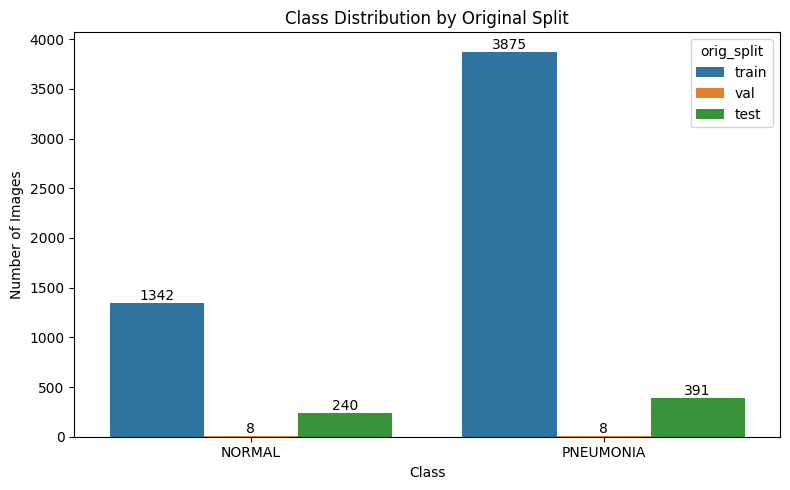

class_name  NORMAL  PNEUMONIA
orig_split                   
test           240        391
train         1342       3875
val              8          8


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image

plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df, x="class_name", hue="orig_split")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Class Distribution by Original Split")
plt.xlabel("Class"); plt.ylabel("Number of Images")
plt.tight_layout(); plt.show()

print(pd.crosstab(df.orig_split, df.class_name))

**Insights**
- The data is imbalanced: train has 1,342 Normal vs 3,875 Pneumonia (about 1 : 2.9, or 74% pneumonia).
- The original val folder has only 8 + 8 images, too few for reliable validation. This is why I re-split in Section 4.
- Test has a different class balance (240 Normal / 391 Pneumonia, 62% pneumonia) than train (74%).
  Accuracy and precision depend on class balance, so recall and specificity will be the fairer metrics to compare across splits.
- **Action:** use class weights during training.

### 3.2 Sample X-rays
Viewing random examples from each class to understand what the model will see.

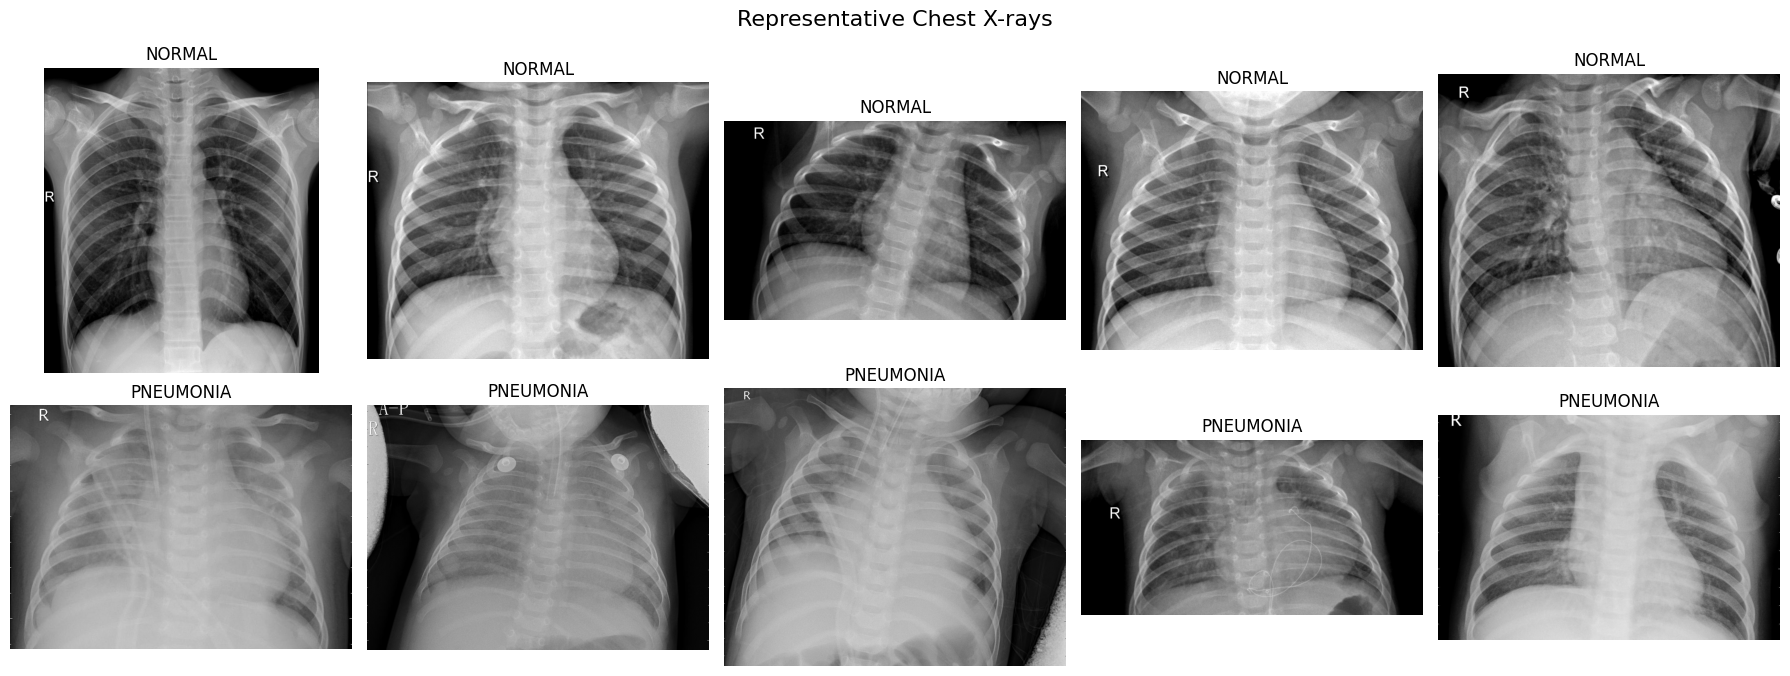

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(18, 7))
for r, cls in enumerate(classes):
    s = df[df.class_name == cls].sample(5, random_state=42)
    for c, (_, row) in enumerate(s.iterrows()):
        axes[r, c].imshow(Image.open(row.path).convert("L"), cmap="gray")
        axes[r, c].set_title(cls)
        axes[r, c].axis("off")
plt.suptitle("Representative Chest X-rays", fontsize=16)
plt.tight_layout(); plt.show()

**Insights**
- Images vary a lot in cropping, zoom, positioning, and exposure.
- Tubes, ECG leads and an "A-P" label appear only on Pneumonia images in this sample, while "R" side markers appear on both classes.
  This is a small sample, but it is a risk: the model could learn these non-lung cues instead of lung opacity.
- **Action:** use Grad-CAM after training to verify the model focuses on the lungs.

### 3.3 Images per Patient
Checking how many X-rays each patient has, which determines how the split must be done.

count    4175.000000
mean        1.404551
std         1.285699
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max        30.000000
dtype: float64
Patients with more than 1 image: 716 of 4175


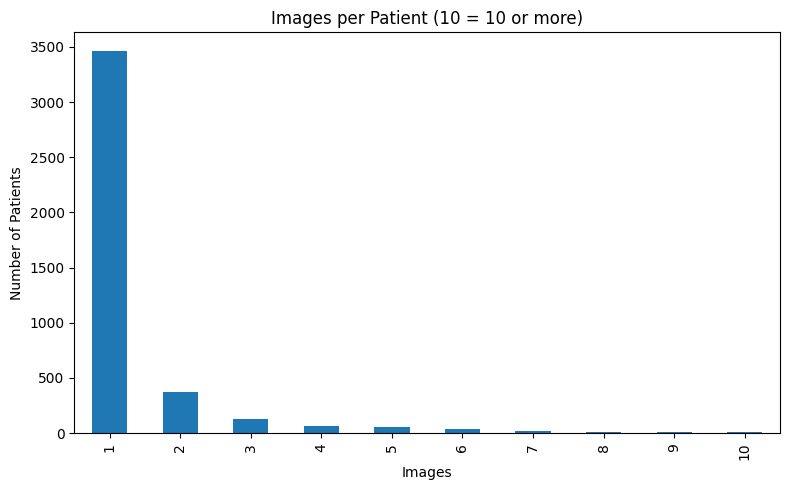

In [ ]:
per_patient = df.groupby("pid_full").size()
print(per_patient.describe())
print("Patients with more than 1 image:", int((per_patient > 1).sum()), "of", len(per_patient))

plt.figure(figsize=(8, 5))
per_patient.clip(upper=10).value_counts().sort_index().plot(kind="bar")
plt.title("Images per Patient (10 = 10 or more)")
plt.xlabel("Images"); plt.ylabel("Number of Patients")
plt.tight_layout(); plt.show()

**Insights**
- Using the subtype-corrected patient ID (Section 2.1), 4,175 patients contribute 5,864 images:
  mean 1.40 images per patient, median 1, maximum 30.
- Most patients (3,459, 82.9%) have a single image. The 716 patients (17.1%) with more than one image account for
  2,405 images, which is 41.0% of the dataset.
- Images from the same patient are highly similar. A random per-image split would put near-copies in both train and
  validation and inflate validation scores.
- **Action:** split by patient (done in Section 4).

### 3.4 Image Size, Brightness, and Contrast
Comparing image dimensions, mean brightness, and contrast (pixel standard deviation) across classes and splits.
Based on a sample of up to 100 images per split and class. The original val folder has only 8 per class, so its boxes are not meaningful.

                  width  height  mean_intensity   contrast
split class                                               
test  NORMAL     1829.0  1394.8      124.400002  60.700001
      PNEUMONIA  1126.7   756.2      118.199997  54.500000
train NORMAL     1660.1  1376.7      122.099998  60.799999
      PNEUMONIA  1235.0   834.7      123.400002  55.200001
val   NORMAL     1479.5  1191.9      123.800003  64.400002
      PNEUMONIA  1217.0   814.0      126.099998  58.799999


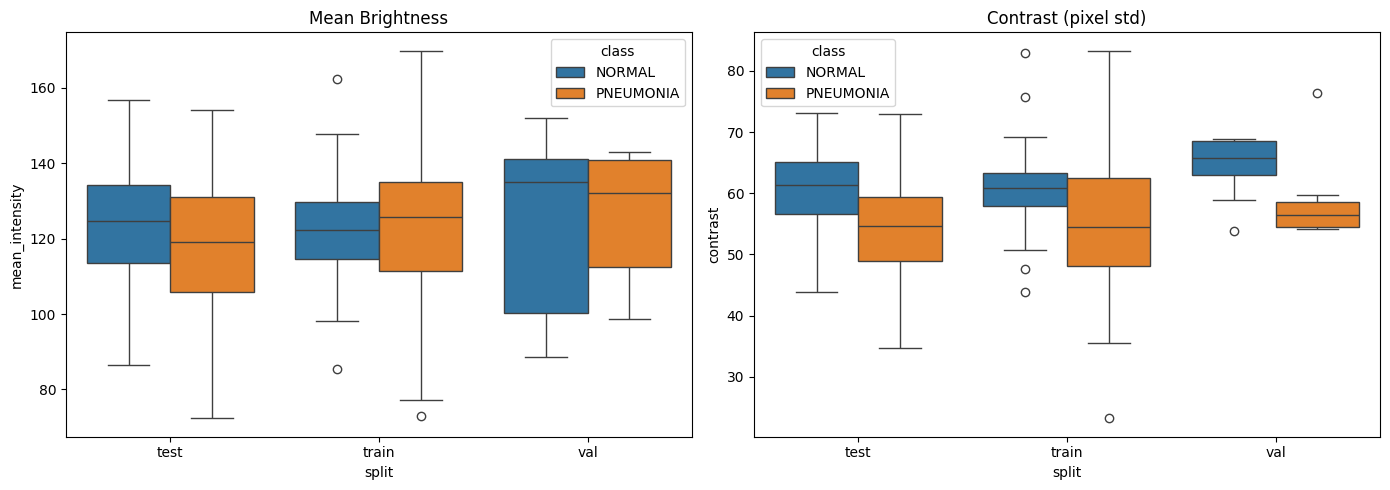

In [ ]:
sample = pd.concat([
    g.sample(min(len(g), 100), random_state=42)
    for _, g in df.groupby(["orig_split", "class_name"])
])

stats = []
for _, r in sample.iterrows():
    with Image.open(r.path) as im:
        w, h = im.size
        arr = np.asarray(im.convert("L").resize((224, 224)), dtype=np.float32)
    stats.append({"split": r.orig_split, "class": r.class_name,
                  "width": w, "height": h,
                  "mean_intensity": arr.mean(), "contrast": arr.std()})
stats_df = pd.DataFrame(stats)

print(stats_df.groupby(["split", "class"])[["width", "height", "mean_intensity", "contrast"]].mean().round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=stats_df, x="split", y="mean_intensity", hue="class", ax=axes[0])
axes[0].set_title("Mean Brightness")
sns.boxplot(data=stats_df, x="split", y="contrast", hue="class", ax=axes[1])
axes[1].set_title("Contrast (pixel std)")
plt.tight_layout(); plt.show()

**Insights**
- **Brightness is similar across splits** (about 118–126 on a 0–255 scale), with heavily overlapping boxes.
  There is no major brightness shift between train and test, so only mild brightness/contrast augmentation is needed.
- **Contrast differs by class:** Pneumonia images have lower contrast (about 55) than Normal (about 61) in every split,
  consistent with hazier lung fields.
- **Image shape differs by class:** in train, Normal images average about 1660 × 1377 (aspect ratio 1.21) while Pneumonia
  images average about 1235 × 835 (aspect ratio 1.48). In test, Normal images are 1.31 and Pneumonia 1.49, so the
  aspect-ratio gap is smaller than in train, although the absolute size gap is larger.
- Resizing every image to a 224 × 224 square stretches the two classes by different amounts, which could leave a
  subtle shortcut based on image shape rather than lung findings.
- **Action:** resize while preserving aspect ratio (pad to a square) instead of stretching.

### 3.5 Pneumonia Subtypes
The filenames identify bacterial vs viral pneumonia. I use this only for analysis, not as training labels.

In [ ]:
pn = df[df.class_name == "PNEUMONIA"].copy()
def subtype(p):
    n = os.path.basename(p).lower()
    return "bacteria" if "bacteria" in n else ("virus" if "virus" in n else "other")
pn["subtype"] = pn.path.apply(subtype)
print(pd.crosstab(pn.orig_split, pn.subtype))

subtype     bacteria  virus
orig_split                 
test             243    148
train           2530   1345
val                8      0


**Insights**
- Train: 2,530 bacterial (65%) and 1,345 viral (35%). Test: 243 bacterial (62%) and 148 viral (38%).
  The subtype mix is similar in train and test.
- The original val folder has 8 bacterial and 0 viral images, another sign it was not usable.
- Viral pneumonia is sometimes reported to be harder to separate from normal X-rays, so recall is reported per subtype.
- **Action:** report recall separately for bacterial and viral pneumonia in the evaluation.

### 3.6 EDA Summary: Decisions Carried Forward
| Finding | Decision |
|---|---|
| Train is 74% pneumonia; test is 62% | Class weights; judge by recall and specificity, not accuracy alone |
| Original val has 16 images | Merge and re-split by patient |
| About 41% of images come from the 17% of patients with multiple images | Patient-level split |
| Image shape differs by class | Aspect-ratio-preserving resize |
| Devices and text markers in some X-rays | Verify with Grad-CAM |
| 35–38% of pneumonia cases are viral | Report per-subtype recall |

## 4. Train / Validation / Test Split

- The **test set is kept exactly as provided** and used only for final evaluation.
- The original train and val folders are merged, because the original val had only 16 images.
- Identical-content duplicates are removed from this pool.
- The pool is re-split by **patient** (`StratifiedGroupKFold`), keeping the class ratio similar in train and val,
  so no patient appears in both. About 1/7 of patients go to validation.
- The exact file lists are saved in Section 5.1 so the split can be reproduced.


In [ ]:
pool_all = df[df.orig_split.isin(["train", "val"])]
pool = pool_all.drop_duplicates("md5").reset_index(drop=True)
print("Duplicate images removed:", len(pool_all) - len(pool))
test_df = df[df.orig_split == "test"]

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=42)
train_idx, val_idx = next(sgkf.split(pool, pool["label"], groups=pool["patient_id"]))
train_df = pool.iloc[train_idx]
val_df = pool.iloc[val_idx]

print("Patients shared by train and val:", len(set(train_df.patient_id) & set(val_df.patient_id)))

new_base = "/content/chest_xray_split"
if os.path.exists(new_base):
    shutil.rmtree(new_base)

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    for _, r in d.iterrows():
        dst = os.path.join(new_base, name, r["class_name"])
        os.makedirs(dst, exist_ok=True)
        shutil.copy(r["path"], os.path.join(dst, os.path.basename(r["path"])))

print("Split complete.")

Duplicate images removed: 27
Patients shared by train and val: 0
Split complete.


**Insights**
- 27 identical-content duplicates were removed from the merged train+val pool.
- 0 patients are shared between train and validation, confirming the patient-level split worked.

## 5. Split Verification
Confirming the final image counts and class balance of each split.

In [ ]:
for name in ["train", "val", "test"]:
    counts = {c: len(os.listdir(os.path.join(new_base, name, c))) for c in classes}
    total = sum(counts.values())
    pn = counts["PNEUMONIA"] / total
    print(f"{name:>5}: {counts}  total={total}  pneumonia share={pn:.1%}")

train: {'NORMAL': 1153, 'PNEUMONIA': 3330}  total=4483  pneumonia share=74.3%
  val: {'NORMAL': 195, 'PNEUMONIA': 528}  total=723  pneumonia share=73.0%
 test: {'NORMAL': 240, 'PNEUMONIA': 391}  total=631  pneumonia share=62.0%


**Insights**
- Final split: **train 4,483** (1,153 Normal / 3,330 Pneumonia), **val 723** (195 / 528), **test 631** (240 / 391).
- Train and validation have almost the same class balance (74.3% vs 73.0% pneumonia), so validation is representative of training.
- Test has a lower pneumonia share (62.0%). Accuracy and precision depend on class balance, so recall and specificity
  are the fairer metrics to compare across splits.
- 27 identical-content duplicates were removed, and no patient appears in both train and validation.

### 5.1 Saving the Exact Split
The list of files in each split is saved, so the split can be reproduced exactly and is included in the GitHub repository.


In [ ]:
MANIFEST = "/content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/split_manifest.csv"

if not os.path.exists(new_base):
    print("Split folders are gone (runtime reset). Don't save anything. Tell me and we'll handle it.")
else:
    rows = []
    for name in ["train", "val", "test"]:
        for cls in classes:
            for f in sorted(os.listdir(os.path.join(new_base, name, cls))):
                if f.lower().endswith(IMG_EXTS):
                    rows.append({"split": name, "class_name": cls, "filename": f})
    pd.DataFrame(rows).to_csv(MANIFEST, index=False)
    print(pd.read_csv(MANIFEST).groupby(["split", "class_name"]).size())

split  class_name
test   NORMAL         240
       PNEUMONIA      391
train  NORMAL        1153
       PNEUMONIA     3330
val    NORMAL         195
       PNEUMONIA      528
dtype: int64


**Insights**
- The saved list matches the verified counts: train 1,153 / 3,330, validation 195 / 528, test 240 / 391 (Normal / Pneumonia).


## 6. Preprocessing and Input Pipeline
Preprocessing standardizes every image into the same model input. The steps are:
1. Decode the image as 3 channels (X-rays are grayscale; the pretrained backbone expects RGB).
2. Resize to 224 × 224 **while preserving aspect ratio** (pad with black instead of stretching).
3. Keep pixel values in the 0–255 range (EfficientNet normalizes internally, so no manual scaling).
4. Batch and prefetch for fast GPU feeding.

Augmentation is applied to **training data only**; validation and test get only steps 1–4.

### 6.1 Setup and Reading the Split Folders

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np, random
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

def folder_to_df(split):
    rows = []
    for cls in classes:
        folder = os.path.join(new_base, split, cls)
        for f in list_images(folder):
            rows.append({"path": os.path.join(folder, f),
                         "label": int(cls == "PNEUMONIA"),
                         "class_name": cls})
    return pd.DataFrame(rows)

train_df = folder_to_df("train")
val_df = folder_to_df("val")
test_df = folder_to_df("test")
print("Train / Val / Test:", len(train_df), len(val_df), len(test_df))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Train / Val / Test: 4483 723 631


**Insights**
- TensorFlow 2.21 detects one GPU (T4), so training will run on the GPU.
- Folder tables match the split verified in Section 5: train 4,483, val 723, test 631.
- A fixed random seed (42) is set for Python, NumPy, and TensorFlow to make results reproducible.

### 6.2 Building the TensorFlow Input Pipeline

In [ ]:
def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize_with_pad(img, IMG_SIZE[0], IMG_SIZE[1])  # keeps aspect ratio
    img = tf.cast(img, tf.float32)                                 # stays in 0-255
    return img, tf.cast(label, tf.float32)

def make_dataset(df, training=False):
    ds = tf.data.Dataset.from_tensor_slices((df["path"].values,
                                             df["label"].values.astype("float32")))
    if training:
        ds = ds.shuffle(len(df), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)

for images, labels in train_ds.take(1):
    print("Batch shape:", images.shape, "| dtype:", images.dtype)
    print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))
    print("Labels in batch:", labels.shape)

Batch shape: (32, 224, 224, 3) | dtype: <dtype: 'float32'>
Pixel range: 0.0 to 255.0
Labels in batch: (32,)


**Insights**
- Each batch has shape (32, 224, 224, 3) in `float32`, with pixel values left in the 0–255 range.
  EfficientNetB0 contains its own normalization layer, so scaling manually would normalize twice.
- The pipeline reads, decodes, resizes, and batches images lazily from disk, so memory use stays small.
- Only the training data is shuffled (reshuffled each epoch); validation and test stay in a fixed order.

### 6.3 Checking the Resize (Aspect Ratio Preserved)

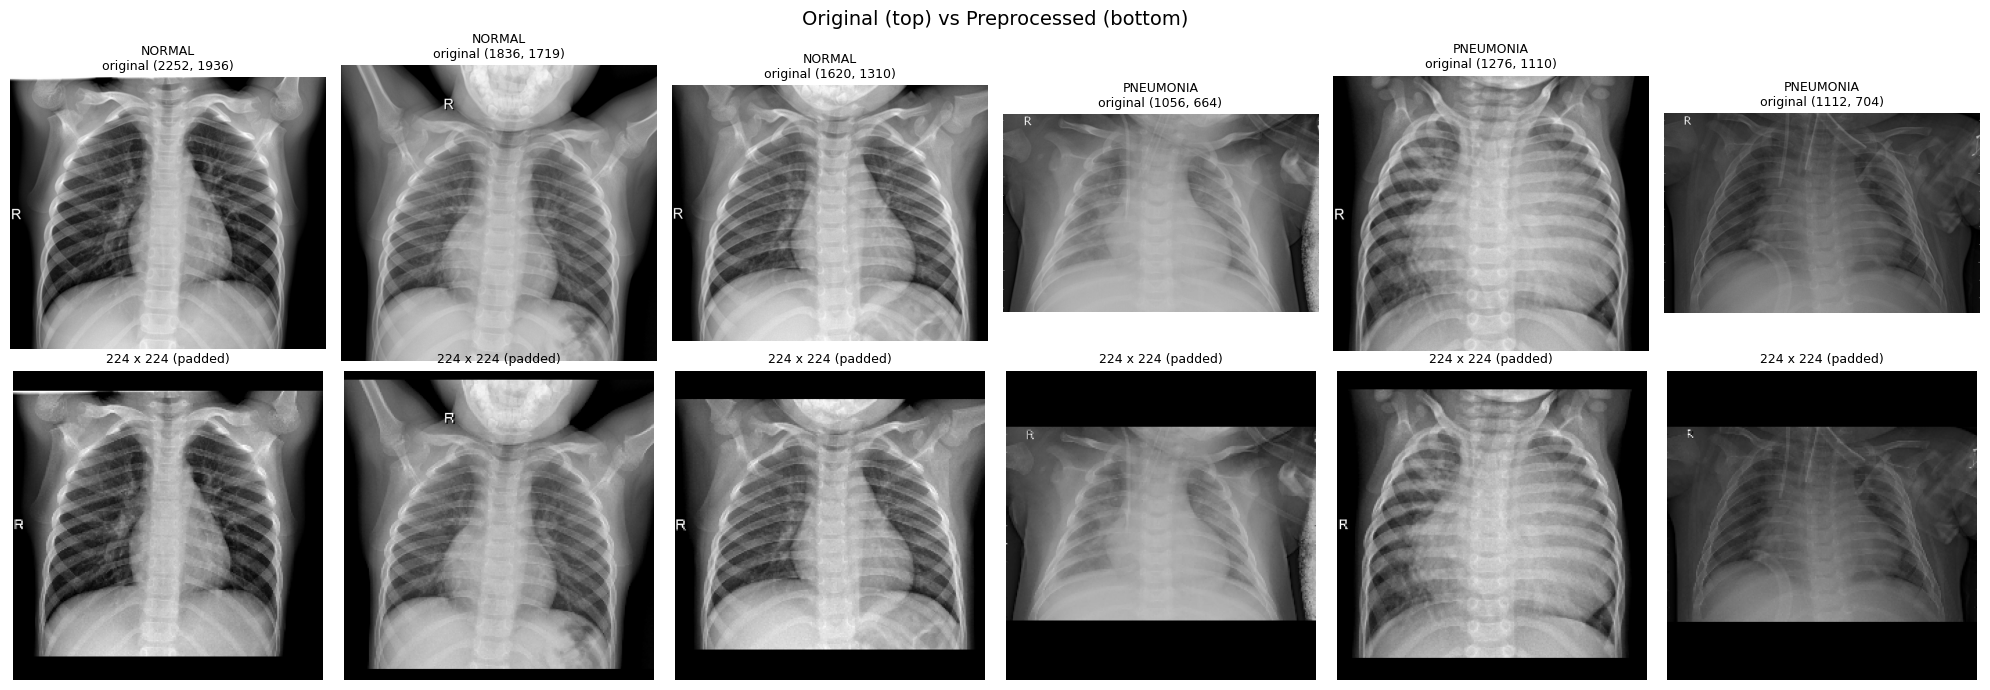

In [ ]:
picks = pd.concat([train_df[train_df.label == 0].sample(3, random_state=SEED),
                   train_df[train_df.label == 1].sample(3, random_state=SEED)])

fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for i, (_, r) in enumerate(picks.iterrows()):
    orig = Image.open(r.path)
    proc, _ = load_image(r.path, r.label)
    axes[0, i].imshow(orig.convert("L"), cmap="gray")
    axes[0, i].set_title(f"{r.class_name}\noriginal {orig.size}", fontsize=9)
    axes[1, i].imshow(tf.cast(proc, tf.uint8))
    axes[1, i].set_title("224 x 224 (padded)", fontsize=9)
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.suptitle("Original (top) vs Preprocessed (bottom)", fontsize=14)
plt.tight_layout(); plt.show()

**Insights**
- Resizing preserves the original aspect ratio, so chest anatomy is not stretched.
- Wide images (mostly Pneumonia) receive black bars above and below, while near-square images (mostly Normal) receive almost none.
- **Risk:** the amount of padding still encodes the original image shape, which differs by class (see EDA 3.4).
  The model could partly learn this shortcut, so Grad-CAM will be used after training to confirm it focuses on the lungs.

### 6.4 Training Augmentation
Mild, anatomy-safe transformations. **No horizontal flip** (the heart sits on the left, and a mirrored X-ray is not realistic).

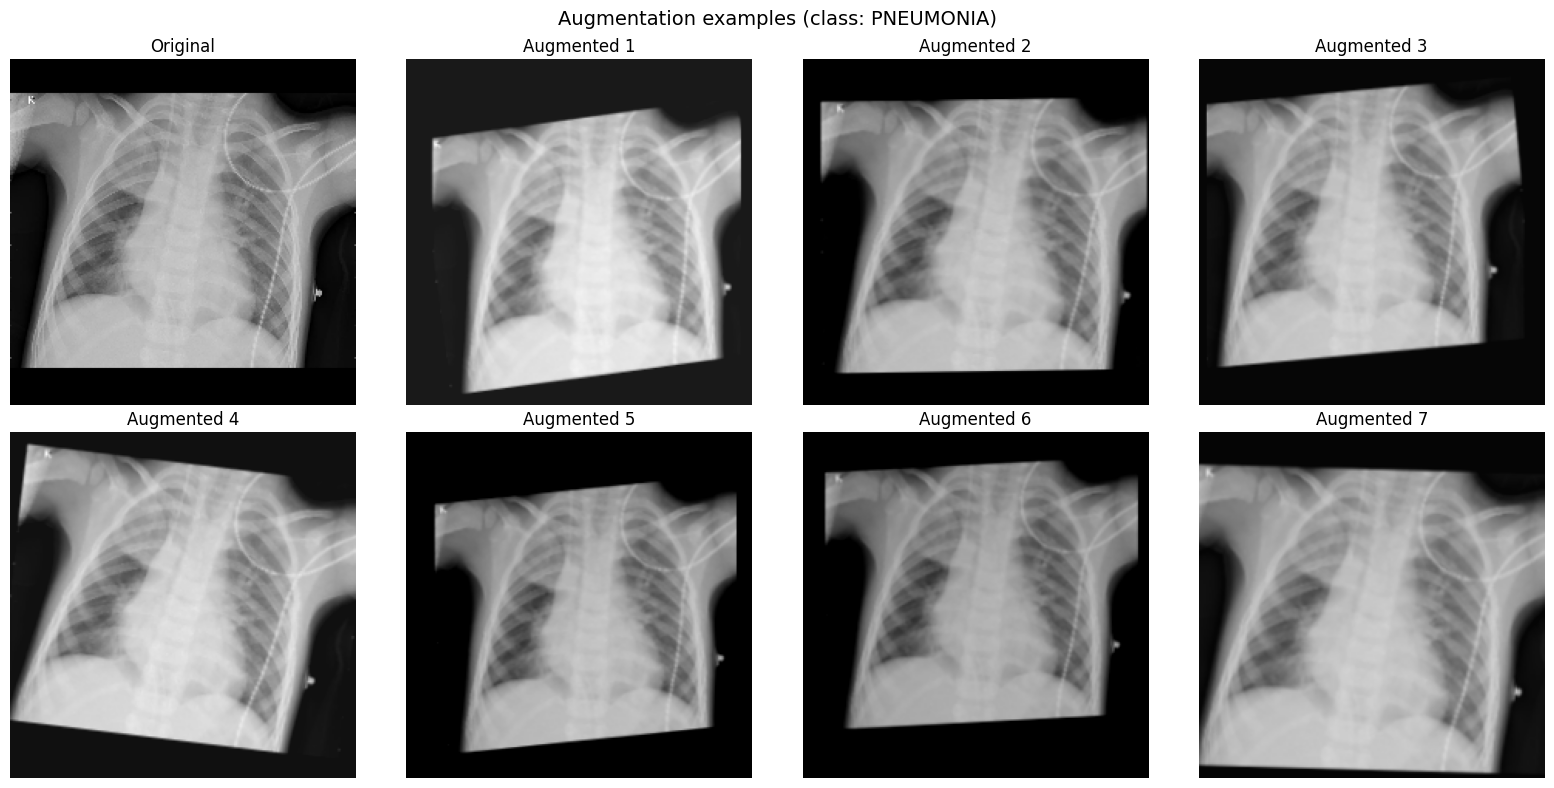

In [ ]:
augmentation = keras.Sequential([
    layers.RandomRotation(0.03, fill_mode="constant", fill_value=0.0),            # about ±11 degrees
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
], name="xray_augmentation")

images, labels = next(iter(train_ds))
img = images[0]

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()
axes[0].imshow(tf.cast(img, tf.uint8)); axes[0].set_title("Original")
for k in range(1, 8):
    aug = augmentation(tf.expand_dims(img, 0), training=True)[0]
    axes[k].imshow(tf.cast(tf.clip_by_value(aug, 0, 255), tf.uint8))
    axes[k].set_title(f"Augmented {k}")
for a in axes: a.axis("off")
plt.suptitle(f"Augmentation examples (class: {'PNEUMONIA' if labels[0] == 1 else 'NORMAL'})", fontsize=14)
plt.tight_layout(); plt.show()

**Insights**
- Augmentation uses small rotations (about ±11°), shifts (5%), zoom (10%), and mild brightness and contrast changes.
- Anatomy remains realistic: the heart stays on the correct side and the ribs and lungs stay clearly visible.
- No horizontal flip is used, since a mirrored chest X-ray is anatomically unrealistic.
- Augmentation is applied to training batches only; validation and test images are never altered.

### 6.5 Class Weights
Computed **from the training set only**, to offset the 74% / 26% imbalance.

In [ ]:
counts = train_df["label"].value_counts().sort_index()
total = len(train_df)
class_weight = {int(c): total / (2 * n) for c, n in counts.items()}

print("Training class counts:\n", counts)
print("\nClass weights:", {k: round(v, 3) for k, v in class_weight.items()})

Training class counts:
 label
0    1153
1    3330
Name: count, dtype: int64

Class weights: {0: 1.944, 1: 0.673}


**Insights**
- Training set: 1,153 Normal and 3,330 Pneumonia (about 1 : 2.9).
- Class weights computed from the training set only: **Normal 1.944, Pneumonia 0.673**.
  A Normal mistake therefore counts about 2.9 times more than a Pneumonia mistake during training.
- Weights are computed on the training split only, so no information leaks from validation or test.

## 7. Model Building: EfficientNetB0 Transfer Learning
**Transfer learning:** instead of training a CNN from scratch on about 4,500 X-rays, I start from EfficientNetB0
pretrained on ImageNet, which already knows edges, textures, and shapes.

**Stage 1 (this section):** the pretrained backbone is **frozen** and only the new classification head is trained.
**Stage 2 (next section):** the last backbone layers are unfrozen and fine-tuned at a very low learning rate.

Architecture: Input → Augmentation (training only) → EfficientNetB0 (includes its own normalization)
→ Global Average Pooling → Dropout → Dense(1, sigmoid) = probability of pneumonia.

### 7.1 Building the Model

In [ ]:
base_model = keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3)
)
base_model.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = augmentation(inputs)                      # only active during training
x = base_model(x, training=False)             # keeps BatchNorm in inference mode
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(1, activation="sigmoid", name="pneumonia_probability")(x)

model = keras.Model(inputs, outputs, name="Pneumonia_EfficientNetB0")
model.summary()

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Pneumonia_EfficientNetB0"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image (InputLayer)              │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xray_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pneumonia_probability (Dense)   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

**Insights**
- The model has 4,050,852 parameters, but only **1,281** are trainable (the final Dense layer: 1,280 weights + 1 bias).
  The other 4,049,571 belong to the frozen ImageNet backbone.
- Training only a small head on pretrained features is fast and lowers overfitting risk on about 4,500 images.
- Augmentation sits inside the model, so it is active only during training.

### 7.2 Stage 1: Training the Classification Head
Checkpoints are saved to Google Drive, so the best model survives a runtime disconnect.

In [ ]:
MODEL_DIR = "/content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models"
os.makedirs(MODEL_DIR, exist_ok=True)

metrics = [
    keras.metrics.BinaryAccuracy(name="accuracy"),
    keras.metrics.Precision(name="precision"),
    keras.metrics.Recall(name="recall"),
    keras.metrics.AUC(name="auc"),
]

model.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=metrics,
)

callbacks = [
    keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/stage1_best.keras",
                                    monitor="val_auc", mode="max", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, verbose=1),
]

history1 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=10, class_weight=class_weight, callbacks=callbacks,
)

Epoch 1/10
141/141 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step - accuracy: 0.7865 - auc: 0.8341 - loss: 0.5021 - precision: 0.8998 - recall: 0.8097
Epoch 1: val_auc improved from None to 0.97033, saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage1_best.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 49s 243ms/step - accuracy: 0.8363 - auc: 0.9209 - loss: 0.3856 - precision: 0.9406 - recall: 0.8321 - val_accuracy: 0.8949 - val_auc: 0.9703 - val_loss: 0.3030 - val_precision: 0.9850 - val_recall: 0.8693 - learning_rate: 0.0010
Epoch 2/10
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 188ms/step - accuracy: 0.8904 - auc: 0.9682 - loss: 0.2490 - precision: 0.9671 - recall: 0.8816
Epoch 2: val_auc improved from 0.97033 to 0.97932, saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/

**Insights**
- Validation AUC rose steadily from 0.970 (epoch 1) to **0.988** (epoch 10) and was still creeping up, so early stopping
  and learning-rate reduction never triggered. The best checkpoint is epoch 10.
- At epoch 10: validation accuracy 0.943, recall 0.941, precision 0.980, AUC 0.988.
- Training accuracy (0.945) is almost equal to validation accuracy (0.943), so there is no sign of overfitting.
  Training metrics are computed with augmentation and dropout active, which makes them slightly pessimistic.
- Precision (0.98) is higher than recall (0.94) at the 0.5 threshold. Class weights make the model careful about Normal cases,
  so the decision threshold will be revisited later with recall as the priority.
- These are validation numbers only. The untouched test set (62% pneumonia) is the real check.

## 8. Fine-Tuning (Stage 2)
The classification head is trained, so I now unfreeze the **last 30 layers** of EfficientNetB0 and train them at a much lower
learning rate (1e-5), letting the pretrained features adapt slightly to chest X-rays. BatchNormalization layers stay frozen
for stability. The Stage 1 checkpoint is kept separately so both stages can be compared on validation.

### 8.1 Saving Stage 1 History and Checking the Starting Point

In [ ]:
pd.DataFrame(history1.history).to_csv(f"{MODEL_DIR}/history_stage1.csv", index=False)
print("Stage 1 history saved:", len(history1.history["val_auc"]), "epochs")

print("Validation metrics before fine-tuning:")
print(model.evaluate(val_ds, return_dict=True, verbose=0))

Stage 1 history saved: 10 epochs
Validation metrics before fine-tuning:
{'accuracy': 0.9432918429374695, 'auc': 0.9879322052001953, 'loss': 0.141969695687294, 'precision': 0.9802761077880859, 'recall': 0.9412878751754761}


**Insights**
- Validation metrics before fine-tuning (AUC 0.988, accuracy 0.943, recall 0.941, precision 0.980) match the end of Stage 1,
  confirming fine-tuning starts from the best Stage 1 model.

### 8.2 Unfreezing the Last Backbone Layers

In [ ]:
base_model.trainable = True
fine_tune_from = len(base_model.layers) - 30

for i, layer in enumerate(base_model.layers):
    layer.trainable = (i >= fine_tune_from) and not isinstance(layer, layers.BatchNormalization)

n_layers = len(base_model.layers)
n_trainable = sum(int(l.trainable) for l in base_model.layers)
print("Backbone layers:", n_layers, "| trainable:", n_trainable)

def make_metrics():
    return [
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]

model.compile(
    optimizer=keras.optimizers.Adam(1e-5),
    loss=keras.losses.BinaryCrossentropy(),
    metrics=make_metrics(),
)
print("Trainable parameters:", sum(int(np.prod(w.shape)) for w in model.trainable_weights))

Backbone layers: 238 | trainable: 23
Trainable parameters: 1484641


**Insights**
- Of the 238 backbone layers, 23 are unfrozen. The last 30 layers were selected, and the BatchNormalization layers among
  them stay frozen.
- Trainable parameters rise from 1,281 (head only) to **1,484,641**. About 2.57 million backbone parameters remain frozen.
- Fine-tuning uses a learning rate of 1e-5, 100 times lower than Stage 1, so the pretrained features are adjusted gently.

### 8.3 Stage 2: Fine-Tuning

In [ ]:
callbacks2 = [
    keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/stage2_best.keras",
                                    monitor="val_auc", mode="max", save_best_only=True, verbose=1),
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5,
                                  restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-8, verbose=1),
]

history2 = model.fit(
    train_ds, validation_data=val_ds,
    epochs=15, class_weight=class_weight, callbacks=callbacks2,
)

pd.DataFrame(history2.history).to_csv(f"{MODEL_DIR}/history_stage2.csv", index=False)

Epoch 1/15
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9410 - auc: 0.9880 - loss: 0.1408 - precision: 0.9822 - recall: 0.9362
Epoch 1: val_auc improved from None to 0.98867, saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage2_best.keras
141/141 ━━━━━━━━━━━━━━━━━━━━ 47s 243ms/step - accuracy: 0.9447 - auc: 0.9887 - loss: 0.1338 - precision: 0.9834 - recall: 0.9414 - val_accuracy: 0.9405 - val_auc: 0.9887 - val_loss: 0.1427 - val_precision: 0.9840 - val_recall: 0.9337 - learning_rate: 1.0000e-05
Epoch 2/15
140/141 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step - accuracy: 0.9459 - auc: 0.9899 - loss: 0.1250 - precision: 0.9875 - recall: 0.9397
Epoch 2: val_auc improved from 0.98867 to 0.98942, saving model to /content/drive/MyDrive/PROJECT/AI Projects/PRAICP-1012/models/stage2_best.keras

Epoch 2: finished saving model to /content/drive/MyDr

**Insights**
- Fine-tuning improved every validation metric except precision, which was unchanged. Validation AUC rose from 0.988 to **0.9927**,
  accuracy from 0.943 to **0.954**, and recall from 0.941 to **0.956**. Validation loss fell from 0.142 to 0.109.
- Recall is the metric that matters most here. It rose by about 1.5 points (roughly 8 images out of 528 in validation), but
  validation recall fluctuates by a similar amount between epochs, so this gain is suggestive rather than conclusive.
- Training and validation stay close (final accuracy 0.963 vs 0.954), so there is only mild overfitting.
- The learning rate was reduced automatically twice (epoch 8 and epoch 14). Early stopping never triggered, and the run
  reached the 15-epoch limit.
- The last five epochs added only about 0.0004 AUC, so the model has plateaued, and more epochs are unlikely to help much.
- The best weights (epoch 15) are saved as `stage2_best.keras`; the Stage 1 checkpoint is kept for comparison.
- Caution: the validation set has 723 images, so a 1-point change is only about 7 images. These are validation numbers;
  the test set is the real check.

## 9. Training History and Stage Comparison
Training and validation curves for both stages, and a direct comparison of the two stages.

### 9.1 Training and Validation Curves
Accuracy, loss, ROC-AUC and recall over all 25 epochs (10 head-only + 15 fine-tuning). The dashed line marks where fine-tuning starts.

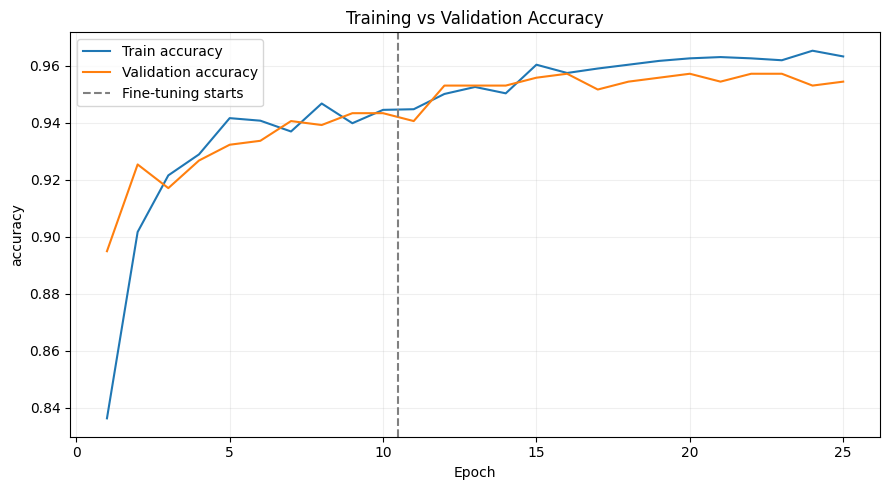

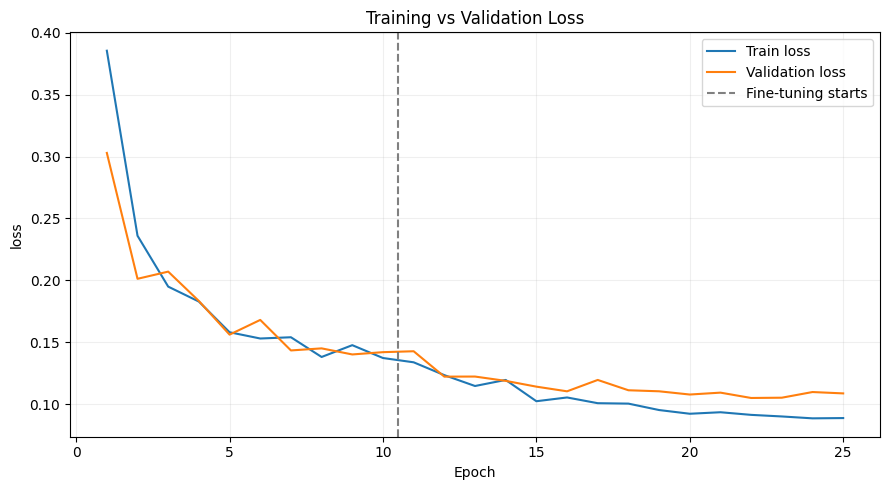

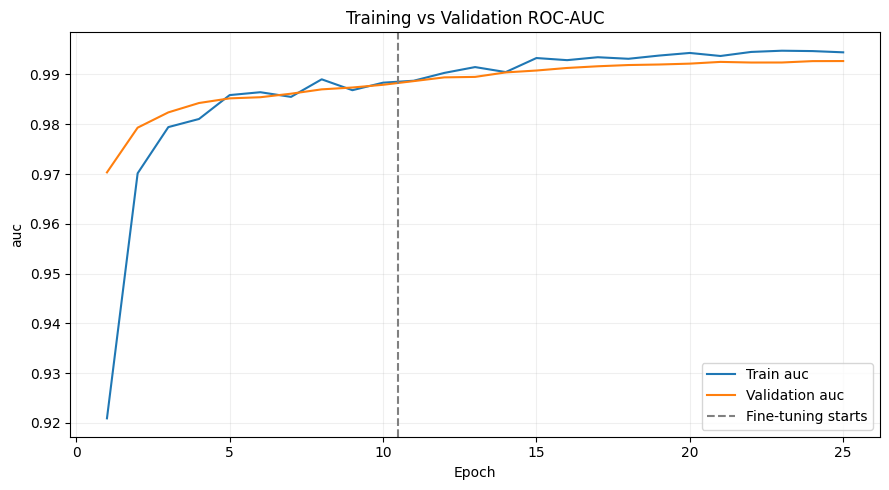

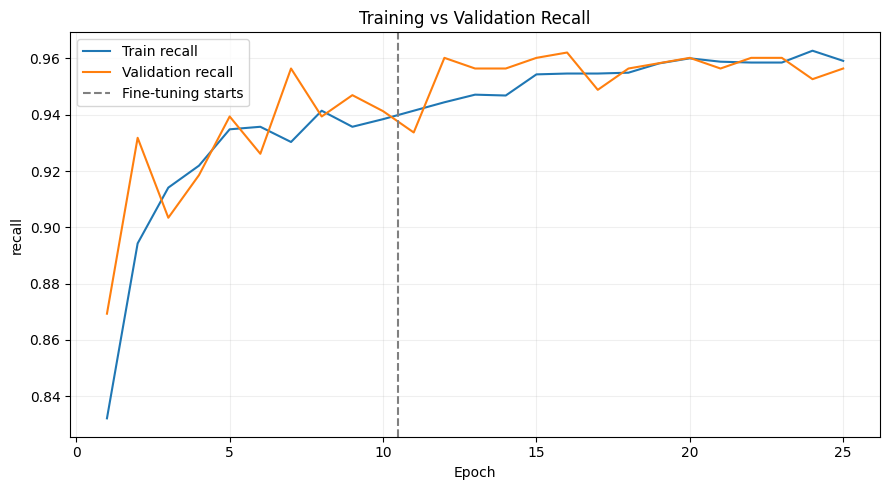

In [ ]:
h1 = pd.read_csv(f"{MODEL_DIR}/history_stage1.csv")
h2 = pd.read_csv(f"{MODEL_DIR}/history_stage2.csv")
hist = pd.concat([h1, h2], ignore_index=True)
hist["epoch"] = range(1, len(hist) + 1)
n1 = len(h1)

def plot_metric(metric, title):
    plt.figure(figsize=(9, 5))
    plt.plot(hist["epoch"], hist[metric], label=f"Train {metric}")
    plt.plot(hist["epoch"], hist[f"val_{metric}"], label=f"Validation {metric}")
    plt.axvline(n1 + 0.5, linestyle="--", color="gray", label="Fine-tuning starts")
    plt.title(title); plt.xlabel("Epoch"); plt.ylabel(metric)
    plt.legend(); plt.grid(alpha=0.2); plt.tight_layout(); plt.show()

for m, t in [("accuracy", "Accuracy"), ("loss", "Loss"), ("auc", "ROC-AUC"), ("recall", "Recall")]:
    plot_metric(m, f"Training vs Validation {t}")

**Insights**
- **Fast early learning:** validation AUC reached 0.970 after one epoch and about 0.988 by epoch 10, which shows how much the
  pretrained backbone already knows.
- **Early epochs, training below validation:** in the first epochs, training accuracy is lower than validation accuracy. Training metrics
  are averaged over the epoch while the weights are still changing, with augmentation and dropout active, whereas validation
  is measured at the end of each epoch with augmentation off.
- **Smooth hand-over to fine-tuning:** there is no drop or instability at epoch 10.5, so the low learning rate (1e-5)
  and the frozen BatchNorm layers worked as intended.
- **Mild overfitting only:** at the end, training accuracy (about 0.963) is about one point above validation (about 0.954), and
  training loss (0.089) is below validation loss (0.109). Validation loss stops improving from about epoch 20, so more
  epochs would add little.
- **AUC and loss improve steadily, recall is noisy:** validation AUC rises and validation loss falls consistently after epoch 10,
  while validation recall bounces between about 0.95 and 0.96 from one epoch to the next.
  With 528 pneumonia images in validation, a 1% move is only about 5 images.

### 9.2 Stage 1 vs Stage 2
Final-epoch metrics of each stage, side by side.

In [ ]:
cols = ["accuracy", "auc", "val_accuracy", "val_precision", "val_recall", "val_auc", "val_loss"]
cmp = pd.DataFrame({"Stage 1": h1.iloc[-1][cols], "Stage 2": h2.iloc[-1][cols]}).round(4)
cmp["Change"] = (cmp["Stage 2"] - cmp["Stage 1"]).round(4)
cmp

,Stage 1,Stage 2,Change
accuracy,0.9445,0.9632,0.0187
auc,0.9884,0.9945,0.0061
val_accuracy,0.9433,0.9544,0.0111
val_precision,0.9803,0.9806,0.0003
val_recall,0.9413,0.9564,0.0151
val_auc,0.9879,0.9927,0.0048
val_loss,0.1420,0.1087,-0.0333


**Insights**
- Fine-tuning improved the model on every validation metric except precision, which stayed the same (0.980):
  AUC 0.988 → **0.993**, accuracy 0.943 → **0.954**, recall 0.941 → **0.956**, and loss 0.142 → **0.109**.
- The AUC and loss gains are consistent across epochs, so they are the more reliable evidence of improvement.
  The recall gain (+1.5 points, about 8 images) is about the size of the epoch-to-epoch fluctuation, so it should be read as
  suggestive, not conclusive.
- Training metrics are measured with augmentation and dropout active, so they are not directly comparable to validation metrics.
- These are validation results. The untouched test set is the real check.

## 10. Decision Threshold and Test Evaluation
The model outputs the probability of pneumonia; the threshold converts it into a prediction. Because a missed pneumonia case
is worse than a false alarm, the threshold is chosen on the **validation set only** with a recall target, and then applied
unchanged to the test set. Recall and specificity are used because, unlike precision and F1, they do not depend on the class mix,
which differs between validation (73% pneumonia) and test (62%).

### 10.1 Choosing the Threshold on Validation
Rule (fixed in advance): the highest threshold that keeps validation recall at or above 0.97.

Check: validation AUC = 0.9926

Chosen threshold (validation recall >= 0.97): 0.29
 threshold  recall  specificity  precision  FN  FP
      0.29  0.9716       0.9333     0.9753  15  13
      0.50  0.9564       0.9487     0.9806  23  10


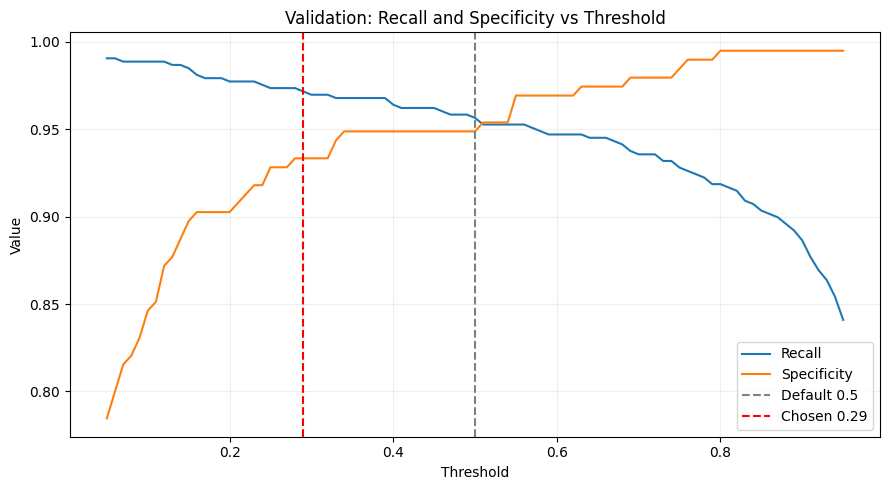

In [ ]:
from sklearn.metrics import roc_auc_score, confusion_matrix

y_val = val_df["label"].values
val_probs = model.predict(val_ds, verbose=0).ravel()
print("Check: validation AUC =", round(roc_auc_score(y_val, val_probs), 4))

def metrics_at(y, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": round(float(t), 2),
            "recall": tp / (tp + fn), "specificity": tn / (tn + fp),
            "precision": tp / (tp + fp) if (tp + fp) else np.nan,
            "FN": int(fn), "FP": int(fp)}

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
tbl = pd.DataFrame([metrics_at(y_val, val_probs, t) for t in grid])

TARGET_RECALL = 0.97
ok = tbl[tbl["recall"] >= TARGET_RECALL]
if ok.empty:
    print("No threshold reaches the recall target on validation.")
else:
    chosen_t = float(ok["threshold"].max())
    print(f"\nChosen threshold (validation recall >= {TARGET_RECALL}): {chosen_t}")
    show = tbl[tbl["threshold"].isin([0.50, chosen_t])].round(4)
    print(show.to_string(index=False))

plt.figure(figsize=(9, 5))
plt.plot(tbl["threshold"], tbl["recall"], label="Recall")
plt.plot(tbl["threshold"], tbl["specificity"], label="Specificity")
plt.axvline(0.5, linestyle="--", color="gray", label="Default 0.5")
if not ok.empty:
    plt.axvline(chosen_t, linestyle="--", color="red", label=f"Chosen {chosen_t}")
plt.title("Validation: Recall and Specificity vs Threshold")
plt.xlabel("Threshold"); plt.ylabel("Value"); plt.legend(); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

**Insights**
- The rule (fixed in advance) selects a threshold of **0.29**: the highest threshold with validation recall of at least 0.97.
- Compared with the default 0.50, threshold 0.29 raises recall from 0.956 to **0.972** (missed pneumonia cases fall from 23 to 15 out of 528),
  while specificity falls from 0.949 to 0.933 (false alarms rise from 10 to 13 out of 195). That is 8 fewer missed cases
  for 3 extra false alarms, a trade that favors recall as intended.
- Precision barely changes (0.981 → 0.975), because pneumonia is the majority class in validation.
- The curves are fairly flat between about 0.35 and 0.50, so the model's probabilities are well separated. Below about 0.3,
  specificity falls off quickly.
- **Caution:** validation has only 195 Normal images, so each false alarm moves specificity by about 0.5 points, and the exact
  threshold is somewhat noisy. Validation was also used to pick the best epoch, so these validation numbers are slightly
  optimistic. The test set is the unbiased check.

### 10.2 Test Set Evaluation
The test set is used once, with the threshold fixed on validation (0.29). Results are reported at both the default 0.50 and 0.29.
Predictions are saved to Drive for later error analysis.

Test ROC-AUC: 0.9618 | PR-AUC: 0.9686


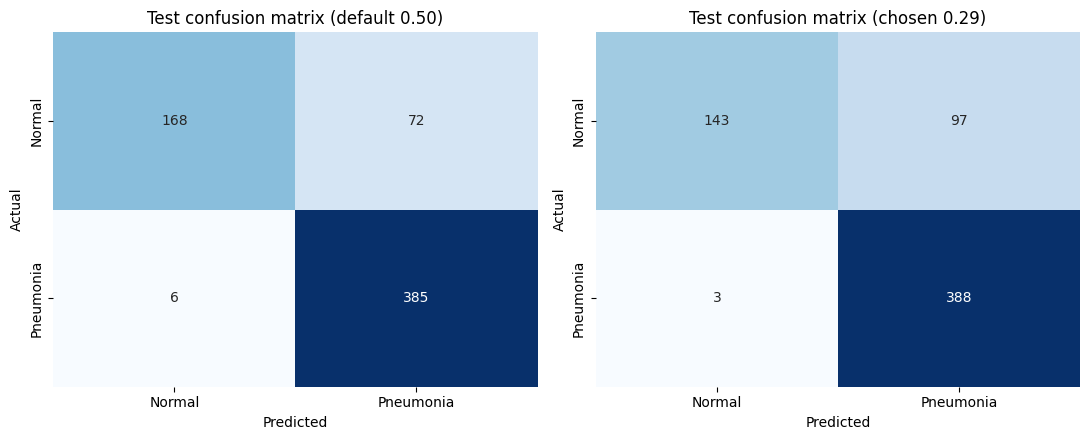

     setting  accuracy  recall  specificity  precision     F1  FN  FP
default 0.50    0.8764  0.9847       0.7000     0.8425 0.9080   6  72
 chosen 0.29    0.8415  0.9923       0.5958     0.8000 0.8858   3  97


In [ ]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

THRESHOLDS = {"default 0.50": 0.50, "chosen 0.29": 0.29}

y_test = test_df["label"].values
test_probs = model.predict(test_ds, verbose=0).ravel()
assert len(test_probs) == len(test_df)

test_out = test_df.copy()
test_out["prob"] = test_probs
test_out["filename"] = test_out["path"].apply(os.path.basename)
test_out["subtype"] = test_out["filename"].apply(
    lambda n: "bacteria" if "bacteria" in n.lower() else ("virus" if "virus" in n.lower() else "normal"))
test_out.to_csv(f"{PROJ}/test_predictions.csv", index=False)

print("Test ROC-AUC:", round(roc_auc_score(y_test, test_probs), 4),
      "| PR-AUC:", round(average_precision_score(y_test, test_probs), 4))

rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, t) in zip(axes, THRESHOLDS.items()):
    pred = (test_probs >= t).astype(int)
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    rows.append({"setting": name, "accuracy": (tp + tn) / len(y_test), "recall": tp / (tp + fn),
                 "specificity": tn / (tn + fp), "precision": tp / (tp + fp),
                 "F1": 2 * tp / (2 * tp + fp + fn), "FN": int(fn), "FP": int(fp)})
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Normal", "Pneumonia"], yticklabels=["Normal", "Pneumonia"])
    ax.set_title(f"Test confusion matrix ({name})"); ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout(); plt.show()
print(pd.DataFrame(rows).round(4).to_string(index=False))

**Insights**
- Test ROC-AUC is **0.962** (95% CI 0.944–0.976) and PR-AUC is 0.969 (a random model would score 0.62, the pneumonia share),
  so the model ranks pneumonia above normal well.
- At the default 0.50: recall **0.985** (385 of 391 pneumonia cases found, 6 missed), specificity **0.700**
  (168 of 240 Normal correct, 72 false alarms), precision 0.843, accuracy 0.876, F1 0.908.
- At the validation-chosen 0.29: recall 0.992 (3 missed), specificity 0.596 (97 false alarms), precision 0.800,
  accuracy 0.842, F1 0.886. Lowering the threshold saved 3 missed cases but cost 25 more false alarms.
- **Validation-to-test gap:** specificity falls from 0.949 (validation) to 0.700 (test), while recall rises from 0.956 to 0.985.
  On the test set the model leans toward predicting pneumonia.
- The threshold chosen on validation did not transfer. It was fixed in advance and not adjusted after seeing test results.
- Possible reasons, investigated in Section 11: test Normals are much wider than train Normals (40% vs 9% have an aspect ratio above 1.4),
  and the model's pneumonia probability rises with image width.

### 10.3 Recall by Pneumonia Subtype and Confidence Intervals
Recall is reported separately for bacterial and viral pneumonia. 95% confidence intervals come from a bootstrap that resamples
**patients** instead of images, because images from one patient are not independent.

In [ ]:
def pid_of(fname, cls):
    stem = os.path.splitext(fname)[0]
    if cls == "PNEUMONIA":
        m = re.match(r"(person\d+)_(bacteria|virus)", stem)
        return f"{m.group(1)}_{m.group(2)}" if m else stem
    return re.sub(r"-\d+$", "", stem)

test_out["pid"] = [pid_of(f, c) for f, c in zip(test_out["filename"], test_out["class_name"])]

for name, t in THRESHOLDS.items():
    pn = test_out[test_out.label == 1].copy()
    pn["detected"] = (pn["prob"] >= t).astype(int)
    print(f"\nRecall by subtype ({name}):")
    print(pn.groupby("subtype")["detected"].agg(["mean", "sum", "count"])
            .rename(columns={"mean": "recall", "sum": "detected", "count": "n"}).round(4))

t_out = test_out.reset_index(drop=True)
idx_groups = list(t_out.groupby("pid").indices.values())
y, p = t_out["label"].values, t_out["prob"].values
rng = np.random.default_rng(42)
res = {k: [] for k in ["AUC", "recall_0.50", "spec_0.50", "recall_0.29", "spec_0.29"]}

for _ in range(1000):
    pick = rng.integers(0, len(idx_groups), len(idx_groups))
    idx = np.concatenate([idx_groups[i] for i in pick])
    yb, pb = y[idx], p[idx]
    if yb.min() == yb.max():
        continue
    res["AUC"].append(roc_auc_score(yb, pb))
    for t in (0.50, 0.29):
        pred = pb >= t
        res[f"recall_{t:.2f}"].append(pred[yb == 1].mean())
        res[f"spec_{t:.2f}"].append((~pred[yb == 0]).mean())

ci = pd.DataFrame({k: [np.mean(v), np.percentile(v, 2.5), np.percentile(v, 97.5)] for k, v in res.items()},
                  index=["mean", "2.5%", "97.5%"]).T.round(4)
print("\nPatient-level bootstrap (1000 resamples):")
print(ci)


Recall by subtype (default 0.50):
          recall  detected    n
subtype                        
bacteria  0.9835       239  243
virus     0.9865       146  148

Recall by subtype (chosen 0.29):
          recall  detected    n
subtype                        
bacteria  0.9918       241  243
virus     0.9932       147  148

Patient-level bootstrap (1000 resamples):
               mean    2.5%   97.5%
AUC          0.9616  0.9440  0.9760
recall_0.50  0.9845  0.9711  0.9949
spec_0.50    0.7000  0.6367  0.7600
recall_0.29  0.9923  0.9828  1.0000
spec_0.29    0.5959  0.5292  0.6583


**Insights**
- Recall is high for both subtypes: bacterial 0.984 (239/243) and viral 0.986 (146/148) at 0.50; 0.992 and 0.993 at 0.29.
  The EDA expectation that viral pneumonia would be harder to detect is not supported, and the differences are within noise
  (only 4 and 2 missed cases).
- 95% CIs from a patient-level bootstrap (1,000 resamples): AUC 0.962 [0.944, 0.976]; at 0.50, recall 0.985 [0.971, 0.995]
  and specificity 0.700 [0.637, 0.760]; at 0.29, recall 0.992 [0.983, 1.000] and specificity 0.596 [0.529, 0.658].
- The recall intervals of the two thresholds overlap heavily, so the 3-case recall gain at 0.29 is within noise, while the
  25 extra false alarms are a real cost.
- Specificity has the widest intervals, since the test set has only 240 Normal images.

## 11. Why Does the Model Over-Call Pneumonia on the Test Set?
Section 10 showed high recall but low test specificity. This section investigates why. It is a diagnosis only. Nothing in the main model or its threshold is changed because of what the test set shows.


### 11.1 Do False Alarms Relate to Image Shape?
In Section 6.3 I noted that padding amounts encode the original image shape, which differs by class. If the model partly uses that
shortcut, Normal test images with a wider shape (more padding) should be more likely to trigger false alarms.

outcome
correct        168
false alarm     72
Name: count, dtype: int64 

             aspect         w         h   prob
outcome                                       
correct       1.305  1919.411  1512.077  0.117
false alarm   1.511  1539.111  1048.514  0.819 

Spearman correlation (aspect ratio vs pneumonia probability, Normals only): 0.501 (p=1.21e-16)
AUC of aspect ratio alone for spotting false alarms: 0.778


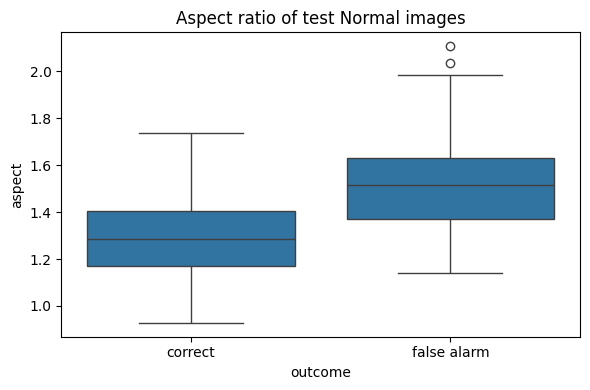

In [ ]:
from scipy.stats import spearmanr

sizes = [Image.open(p).size for p in test_out["path"]]
test_out["w"] = [s[0] for s in sizes]
test_out["h"] = [s[1] for s in sizes]
test_out["aspect"] = test_out["w"] / test_out["h"]

nrm = test_out[test_out.label == 0].copy()
nrm["outcome"] = np.where(nrm["prob"] >= 0.5, "false alarm", "correct")

print(nrm["outcome"].value_counts(), "\n")
print(nrm.groupby("outcome")[["aspect", "w", "h", "prob"]].mean().round(3), "\n")

rho, pval = spearmanr(nrm["aspect"], nrm["prob"])
print(f"Spearman correlation (aspect ratio vs pneumonia probability, Normals only): {rho:.3f} (p={pval:.3g})")
print("AUC of aspect ratio alone for spotting false alarms:",
      round(roc_auc_score((nrm["outcome"] == "false alarm").astype(int), nrm["aspect"]), 3))

plt.figure(figsize=(6, 4))
sns.boxplot(data=nrm, x="outcome", y="aspect")
plt.title("Aspect ratio of test Normal images"); plt.tight_layout(); plt.show()

**Insights**
- Among the 240 Normal test images, the 72 false alarms (at 0.50) are clearly wider than the 168 correct ones
  (mean aspect ratio 1.51 vs 1.31) and smaller in pixels (about 1539 × 1049 vs 1919 × 1512).
- Aspect ratio alone separates false alarms from correct Normals with AUC 0.78 (0.5 would mean no relationship), and it correlates
  with the predicted pneumonia probability (Spearman 0.50, p ≈ 1e-16; 0 would mean no relationship).
- In this dataset Pneumonia images are wider and smaller than Normal ones (EDA 3.4), so the model's pneumonia probability
  for Normal images appears to track image shape and size, not only lung findings.
- This is an association, not proof. Wide, small Normal images may also differ genuinely (acquisition device, positioning).
  Grad-CAM (11.2) and the validation check (11.1b) examine this further.

#### 11.1b Does the Pattern Also Appear in Validation?
Repeating the shape-vs-probability correlation on validation Normals, to see whether the effect is specific to the test set.

In [ ]:
val_out = val_df.copy()
val_out["prob"] = val_probs
val_out["aspect"] = [w / h for w, h in (Image.open(p).size for p in val_out["path"])]

vn = val_out[val_out.label == 0]
rho_v, p_v = spearmanr(vn["aspect"], vn["prob"])
print(f"Validation Normals (n={len(vn)}): Spearman aspect vs probability = {rho_v:.3f} (p={p_v:.3g})")
print(f"Test Normals for comparison (n=240): 0.501")

Validation Normals (n=195): Spearman aspect vs probability = 0.213 (p=0.00275)
Test Normals for comparison (n=240): 0.501


#### 11.1c Image Shape Across Splits
Comparing how wide Normal and Pneumonia images are in train, validation and test.

In [ ]:
def aspects(d):
    return np.array([w / h for w, h in (Image.open(p).size for p in d["path"])])

for cls_name, lab in [("Normal", 0), ("Pneumonia", 1)]:
    for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
        a = aspects(d[d.label == lab])
        print(f"{cls_name:>9} {name:>5} (n={len(a):4d}): median aspect {np.median(a):.2f} | share > 1.4: {(a > 1.4).mean():.1%}")

   Normal train (n=1153): median aspect 1.22 | share > 1.4: 8.8%
   Normal   val (n= 195): median aspect 1.23 | share > 1.4: 11.3%
   Normal  test (n= 240): median aspect 1.35 | share > 1.4: 40.0%
Pneumonia train (n=3330): median aspect 1.49 | share > 1.4: 66.2%
Pneumonia   val (n= 528): median aspect 1.49 | share > 1.4: 69.1%
Pneumonia  test (n= 391): median aspect 1.51 | share > 1.4: 69.1%


**Insights**
- Among Normal images, the model's pneumonia probability rises with image aspect ratio in both validation (Spearman 0.213, p=0.003, n=195)
  and test (0.501, n=240). The shape association is part of the model's behavior, not a test-set quirk.
- Pneumonia shape is stable across splits (66–69% of images wider than 1.4), but **Normal shape is not**: 40.0% of test Normals
  are wider than 1.4, against 8.8% in train and 11.3% in validation. Test Normals are less like the Normals the model trained on.
- In train, about 96% of images wider than 1.4 are Pneumonia. In test, only about 74% are. A "wide means pneumonia" pattern learned in
  training therefore fails on test and likely contributes to the lower test specificity.
- This is an association, not proof. Wide Normal images may also differ in acquisition device or positioning.

#### 11.1d Wide vs Narrow Normals: False-Alarm Rate
If shape drives the false alarms, Normals wider than 1.4 should be flagged as pneumonia far more often than narrower ones.

In [ ]:
nrm = test_out[test_out.label == 0].copy()
nrm["wide"] = nrm["aspect"] > 1.4

for t in (0.50, 0.29):
    nrm["fa"] = nrm["prob"] >= t
    print(f"\nThreshold {t}:")
    print(nrm.groupby("wide")["fa"]
             .agg(false_alarm_rate="mean", false_alarms="sum", n="count").round(3))


Threshold 0.5:
       false_alarm_rate  false_alarms    n
wide                                      
False             0.146            21  144
True              0.531            51   96

Threshold 0.29:
       false_alarm_rate  false_alarms    n
wide                                      
False             0.250            36  144
True              0.635            61   96


**Insights**
- Image width matters a lot. At the default 0.50, narrow Normals (aspect ratio ≤ 1.4, n=144) get a false-alarm rate of **14.6%**
  (specificity 0.854), while wide Normals (> 1.4, n=96) get **53.1%** (specificity 0.469). At the chosen 0.29 the rates are
  25.0% and 63.5%.
- Wide Normals are 40% of the Normal test images but produce 51 of the 72 false alarms (71%) at 0.50.
- Shape does not explain everything. Even narrow test Normals are flagged 14.6% of the time, about three times the validation
  false-alarm rate (5.1%).
- As an illustration only, not a causal estimate: if wide Normals were flagged at the narrow rate, test specificity would be about 0.85 instead of 0.70.
- This is still an association. Wide Normal images may also differ in acquisition device or positioning.

### 11.2 Grad-CAM: Where Does the Model Look?
Grad-CAM highlights the image regions that push the prediction toward pneumonia. It shows whether the model looks at the lungs or at
irrelevant areas such as padding, markers and devices.

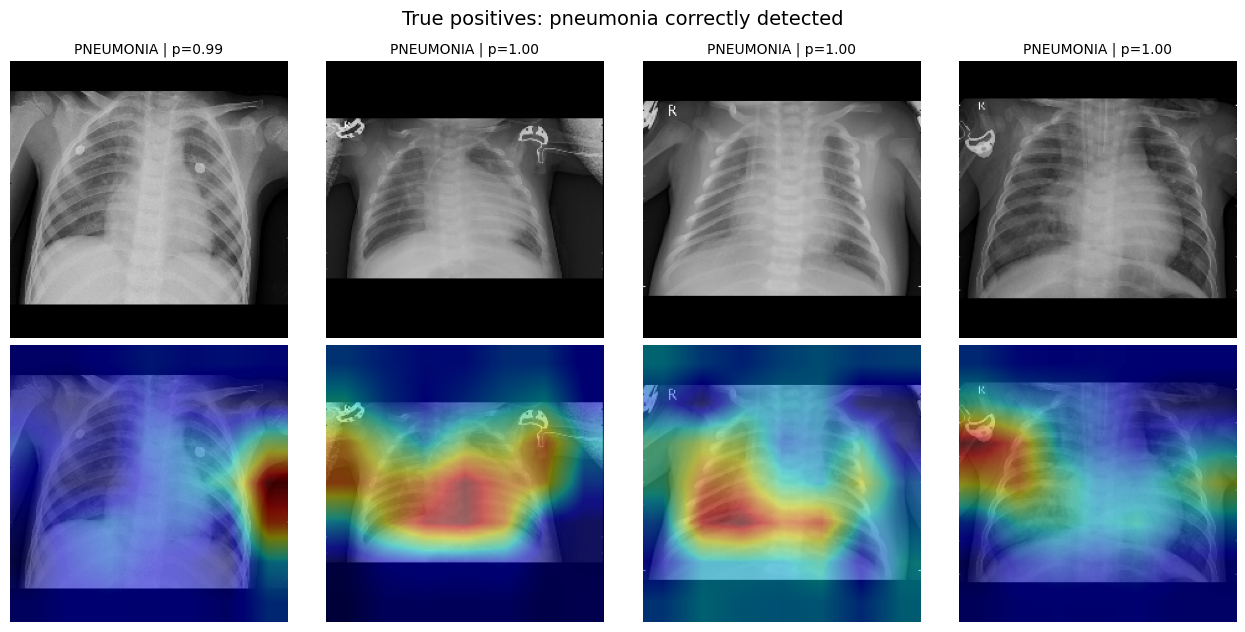

In [ ]:
base = next(l for l in model.layers if isinstance(l, keras.Model) and "efficientnet" in l.name.lower())
gap_layer = next(l for l in model.layers if isinstance(l, layers.GlobalAveragePooling2D))
head = model.get_layer("pneumonia_probability")

def gradcam(img):                       # img: (224, 224, 3) float32 in 0-255
    x = tf.convert_to_tensor(img[None])
    with tf.GradientTape() as tape:
        conv = base(x, training=False)
        tape.watch(conv)
        score = head(gap_layer(conv))[:, 0]
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0]
    cam = (cam / (tf.reduce_max(cam) + 1e-8)).numpy()
    return cam, float(score[0])

def show_cases(df_cases, title, n=4):
    d = df_cases.head(n)
    fig, axes = plt.subplots(2, len(d), figsize=(3.2 * len(d), 6.4))
    axes = np.atleast_2d(axes).reshape(2, -1)
    for j, (_, r) in enumerate(d.iterrows()):
        img, _ = load_image(r["path"], r["label"])
        cam, p = gradcam(img.numpy())
        cam_up = tf.image.resize(cam[..., None], IMG_SIZE).numpy()[..., 0]
        axes[0, j].imshow(tf.cast(img, tf.uint8)); axes[0, j].axis("off")
        axes[0, j].set_title(f"{r['class_name']} | p={p:.2f}", fontsize=10)
        axes[1, j].imshow(tf.cast(img, tf.uint8)); axes[1, j].imshow(cam_up, cmap="jet", alpha=0.45)
        axes[1, j].axis("off")
    plt.suptitle(title, fontsize=14); plt.tight_layout(); plt.show()

rs = 42
tp = test_out[(test_out.label == 1) & (test_out.prob >= 0.5)].sample(4, random_state=rs)
fp = test_out[(test_out.label == 0) & (test_out.prob >= 0.5)].sample(4, random_state=rs)
tn = test_out[(test_out.label == 0) & (test_out.prob < 0.5)].sample(4, random_state=rs)
fn = test_out[(test_out.label == 1) & (test_out.prob < 0.5)]

show_cases(tp, "True positives: pneumonia correctly detected")

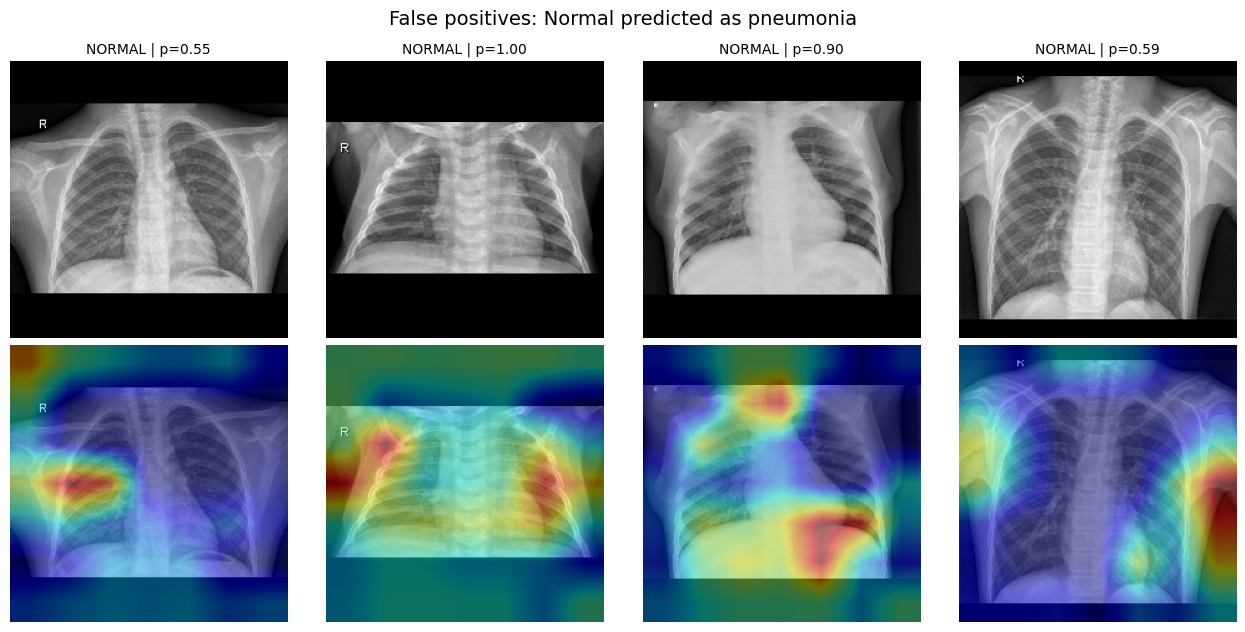

In [ ]:
show_cases(fp, "False positives: Normal predicted as pneumonia")

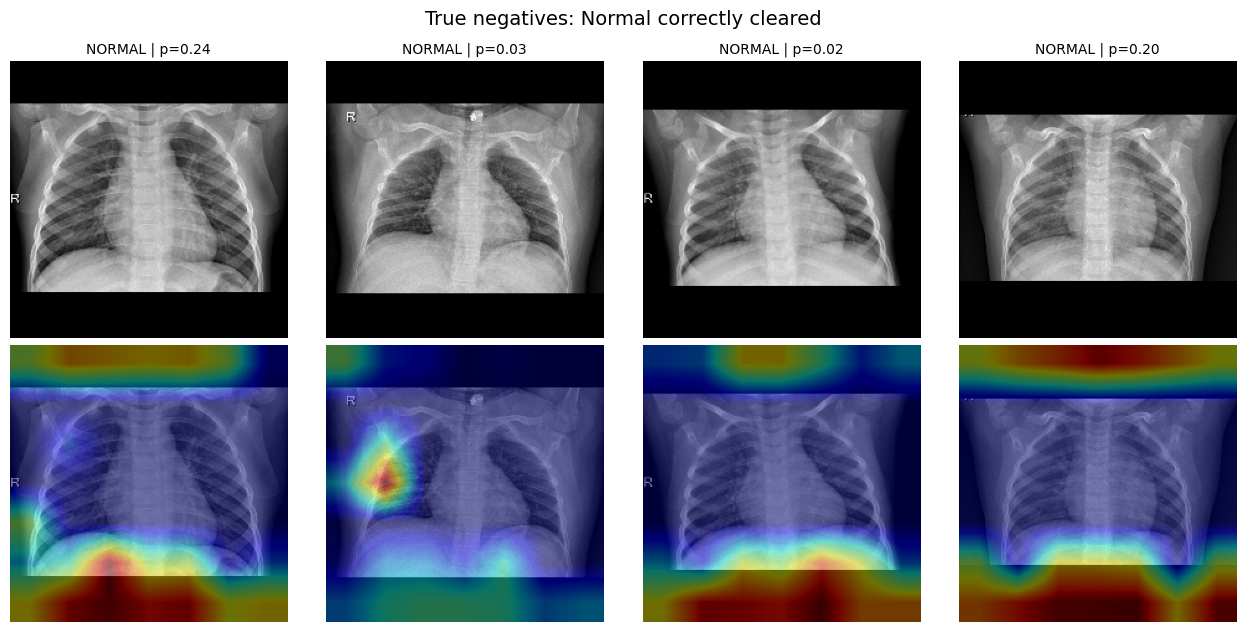

In [ ]:
show_cases(tn, "True negatives: Normal correctly cleared")

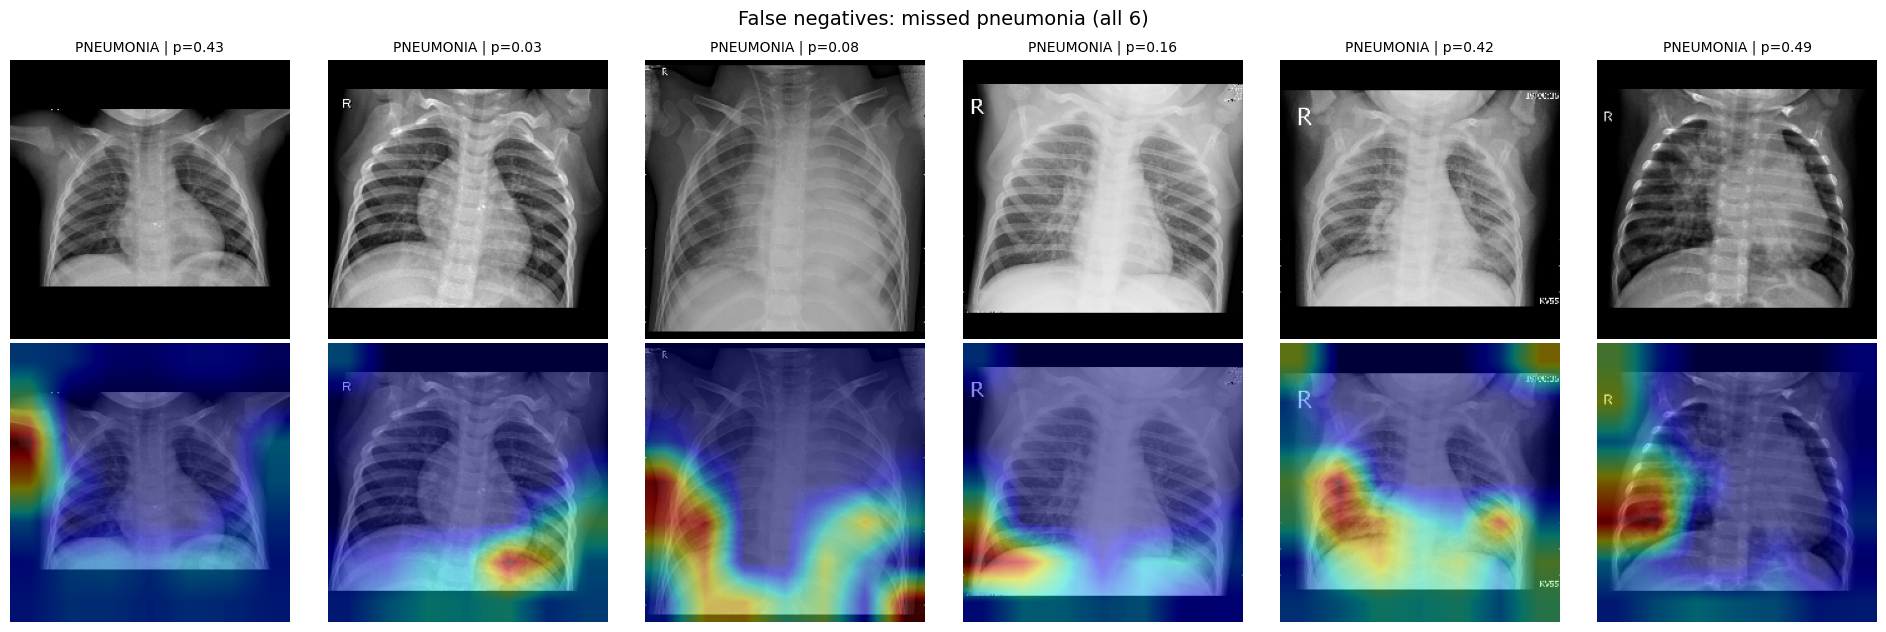

In [ ]:
show_cases(fn, "False negatives: missed pneumonia (all 6)", n=6)

**Insights** (18 random test cases; Grad-CAM is coarse, a 7 × 7 map stretched to 224 × 224)
- **True positives (4):** attention is only partly on the lungs. In two cases the strongest heat is on the lower and central
  lung fields, but in the other two it sits on non-lung structures (the chest-wall edge in one, an ECG clip and shoulder in the other).
  All four have probability 0.99–1.00, so the model is confident even when the heat is not on the lungs.
- **False positives (4 Normals, p = 0.55–1.00):** the heat falls on a mix of lateral lung edges, chest wall, neck and upper abdomen.
  No single obvious pattern, and the heat is not mainly on the padding.
- **True negatives (4 Normals, p = 0.02–0.24):** in three of the four, the strongest positive contribution comes from the black
  padding at the top or bottom of the image, and the lungs themselves are mostly cool. Padding therefore does feed into the pneumonia score,
  even when the final call is correct. Zero-padding borders can also create edge artifacts in convolutional features, so this is suggestive, not conclusive.
- **False negatives (all 6, p = 0.03–0.49):** three are close to the threshold (p = 0.42, 0.43, 0.49), which is why the chosen 0.29 threshold
  recovers exactly those three. The other three (p = 0.03, 0.08, 0.16) are confidently missed. In most of these the heat falls at lower or lateral edges, not in the central lung fields.
- **Overall:** the heatmaps do not show clean, lung-focused attention. Together with Section 11.1 (false alarms concentrated in wide images),
  this supports the view that the model partly relies on non-lung cues such as image shape, padding, devices and chest-wall edges.
  It does not prove it, and the sample is small.

## 12. Extra Experiment: Removing the Image-Shape Cue
Section 11 suggested that the main model partly uses image shape: wide Normal X-rays are flagged as pneumonia far more often.
In the main model, narrow images get black bars (padding), which can reveal the original shape.
This experiment trains the same model again, but cuts a **square from the center** of each X-ray instead of padding it, so there are no black bars.
The main model stays the primary result, because its test numbers were already seen. This model is reported as an exploratory comparison only.

### 12.1 Center-Crop Preprocessing
Each image is cropped to a centered square (side = the shorter side), then resized to 224 × 224. Wide images lose some of their left and right edges.

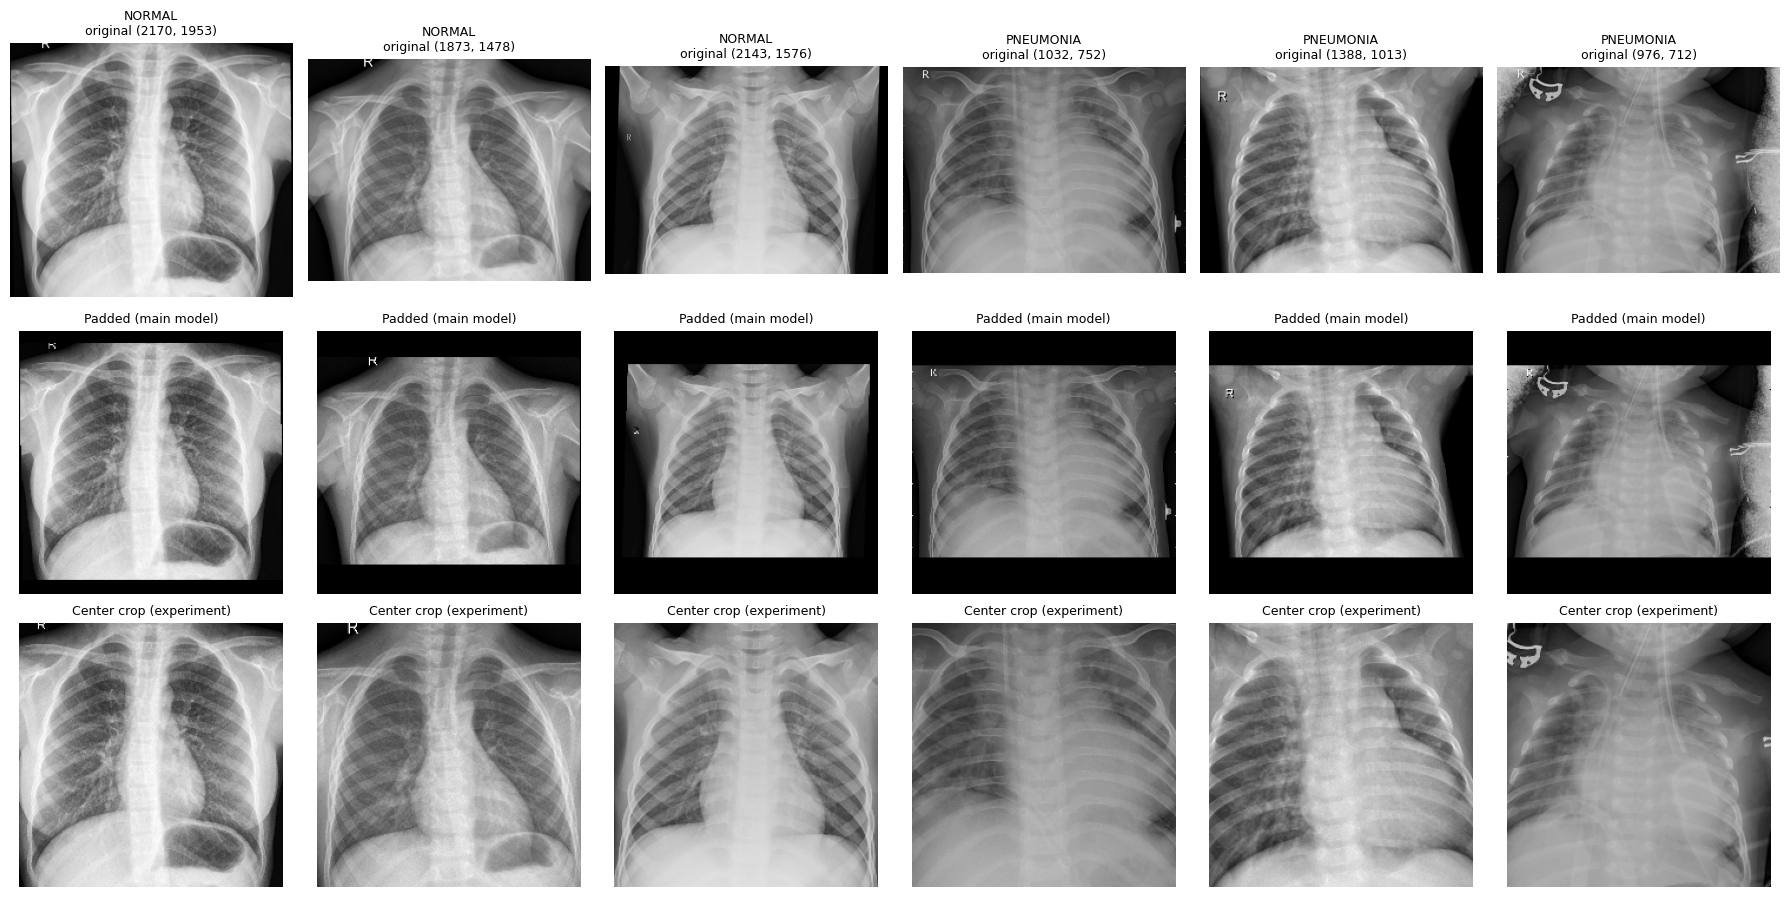

In [7]:
def load_image_crop(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    h, w = tf.shape(img)[0], tf.shape(img)[1]
    s = tf.minimum(h, w)
    top, left = (h - s) // 2, (w - s) // 2
    img = tf.image.crop_to_bounding_box(img, top, left, s, s)
    img = tf.image.resize(img, IMG_SIZE)
    return tf.cast(img, tf.float32), tf.cast(label, tf.float32)

def make_dataset_crop(d, training=False):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values.astype("float32")))
    if training:
        ds = ds.shuffle(len(d), seed=SEED, reshuffle_each_iteration=True)
    return ds.map(load_image_crop, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

picks = pd.concat([test_df[test_df.label == 0].sample(3, random_state=SEED),
                   test_df[test_df.label == 1].sample(3, random_state=SEED)])

fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for i, (_, r) in enumerate(picks.iterrows()):
    orig = Image.open(r["path"])
    pad, _ = load_image(r["path"], r["label"])
    crop, _ = load_image_crop(r["path"], r["label"])
    axes[0, i].imshow(orig.convert("L"), cmap="gray"); axes[0, i].set_title(f"{r['class_name']}\noriginal {orig.size}", fontsize=9)
    axes[1, i].imshow(tf.cast(pad, tf.uint8)); axes[1, i].set_title("Padded (main model)", fontsize=9)
    axes[2, i].imshow(tf.cast(crop, tf.uint8)); axes[2, i].set_title("Center crop (experiment)", fontsize=9)
    for k in range(3):
        axes[k, i].axis("off")
plt.tight_layout(); plt.show()

**Insights**
- The center crop produces square images with no black bars, and the lungs remain fully visible in the six examples.
- Wide images lose part of their left and right edges (for example the shoulders and the outer lung borders). This is the cost of the crop.

### 12.2 Training the Center-Crop Model: Stage 1 (Head Only)
Same recipe as the main model: frozen EfficientNetB0, same augmentation, same class weights, same learning rate.

In [8]:
counts = train_df["label"].value_counts().sort_index()
cw = {int(c): len(train_df) / (2 * n) for c, n in counts.items()}
print("Class weights:", {k: round(v, 3) for k, v in cw.items()})

def make_metrics():
    return [
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]

aug = keras.Sequential([
    layers.RandomRotation(0.03, fill_mode="constant", fill_value=0.0),
    layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0),
    layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0),
    layers.RandomContrast(0.15),
    layers.RandomBrightness(0.10),
], name="xray_augmentation_crop")

keras.utils.set_random_seed(SEED)
abl_base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_shape=(*IMG_SIZE, 3))
abl_base.trainable = False

inp = keras.Input(shape=(*IMG_SIZE, 3), name="image")
x = aug(inp)
x = abl_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
out = layers.Dense(1, activation="sigmoid", name="pneumonia_probability")(x)
abl_model = keras.Model(inp, out, name="Pneumonia_EfficientNetB0_CenterCrop")

abl_train = make_dataset_crop(train_df, training=True)
abl_val = make_dataset_crop(val_df)
abl_test = make_dataset_crop(test_df)

abl_model.compile(optimizer=keras.optimizers.Adam(1e-3),
                  loss=keras.losses.BinaryCrossentropy(), metrics=make_metrics())

cb1 = [
    keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/crop_stage1_best.keras", monitor="val_auc", mode="max", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=4, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2),
]
h1 = abl_model.fit(abl_train, validation_data=abl_val, epochs=10, class_weight=cw, callbacks=cb1, verbose=2)
pd.DataFrame(h1.history).to_csv(f"{MODEL_DIR}/crop_history_stage1.csv", index=False)
print("Best validation AUC (stage 1):", round(max(h1.history["val_auc"]), 4))

Class weights: {0: 1.944, 1: 0.673}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Epoch 1/10
141/141 - 46s - 328ms/step - accuracy: 0.8057 - auc: 0.9053 - loss: 0.4102 - precision: 0.9368 - recall: 0.7919 - val_accuracy: 0.8451 - val_auc: 0.9655 - val_loss: 0.3574 - val_precision: 0.9906 - val_recall: 0.7955 - learning_rate: 0.0010
Epoch 2/10
141/141 - 37s - 261ms/step - accuracy: 0.9083 - auc: 0.9692 - loss: 0.2418 - precision: 0.9753 - recall: 0.8994 - val_accuracy: 0.8700 - val_auc: 0.9738 - val_loss: 0.3091 - val_precision: 0.9932 - val_recall: 0.8277 - learning_rate: 0.0010
Epoch 3/10
141/141 - 41s - 289ms/step - accuracy: 0.9188 - auc: 0.9781 - loss: 0.2024 - precision: 0.9796 - recall: 0.9096 - val_accuracy: 0.9212 - val_auc: 0.9767 - val_loss: 0.2488 - val_precision: 0.9876 - val_recall: 0.9034 - learning_rate: 0.0010
Epoch 4/10
141/141 - 41s - 289ms/step - accuracy: 0.9226 - auc: 0.9793 - loss: 0.1901 - precision: 0.9776 - recall: 0.9168 - val_accuracy: 0.8963 - val_auc: 

**Insights**
- Stage 1 reached a best validation AUC of **0.981**, below the main model's 0.988 at the same stage. Validation recall at the end was about 0.91 (main model: 0.94).
- Training behaved normally: accuracy and AUC rose steadily, and the learning rate dropped once, from epoch 9 onward.

### 12.3 Center-Crop Model: Stage 2 (Fine-Tuning)
Same as the main model: the last 30 backbone layers unfrozen (BatchNorm frozen), learning rate 1e-5.

In [9]:
abl_base.trainable = True
fine_from = len(abl_base.layers) - 30
for i, l in enumerate(abl_base.layers):
    l.trainable = (i >= fine_from) and not isinstance(l, layers.BatchNormalization)
print("Trainable backbone layers:", sum(int(l.trainable) for l in abl_base.layers))

abl_model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss=keras.losses.BinaryCrossentropy(), metrics=make_metrics())

cb2 = [
    keras.callbacks.ModelCheckpoint(f"{MODEL_DIR}/crop_stage2_best.keras", monitor="val_auc", mode="max", save_best_only=True),
    keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=5, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.3, patience=2, min_lr=1e-8),
]
h2 = abl_model.fit(abl_train, validation_data=abl_val, epochs=15, class_weight=cw, callbacks=cb2, verbose=2)
pd.DataFrame(h2.history).to_csv(f"{MODEL_DIR}/crop_history_stage2.csv", index=False)
print("Best validation AUC (stage 2):", round(max(h2.history["val_auc"]), 4))

Trainable backbone layers: 23
Epoch 1/15
141/141 - 57s - 401ms/step - accuracy: 0.9418 - auc: 0.9867 - loss: 0.1446 - precision: 0.9858 - recall: 0.9351 - val_accuracy: 0.9322 - val_auc: 0.9818 - val_loss: 0.2036 - val_precision: 0.9898 - val_recall: 0.9167 - learning_rate: 1.0000e-05
Epoch 2/15
141/141 - 33s - 234ms/step - accuracy: 0.9420 - auc: 0.9873 - loss: 0.1392 - precision: 0.9836 - recall: 0.9375 - val_accuracy: 0.9308 - val_auc: 0.9834 - val_loss: 0.1943 - val_precision: 0.9898 - val_recall: 0.9148 - learning_rate: 1.0000e-05
Epoch 3/15
141/141 - 34s - 238ms/step - accuracy: 0.9462 - auc: 0.9891 - loss: 0.1284 - precision: 0.9858 - recall: 0.9411 - val_accuracy: 0.9350 - val_auc: 0.9839 - val_loss: 0.1875 - val_precision: 0.9898 - val_recall: 0.9205 - learning_rate: 1.0000e-05
Epoch 4/15
141/141 - 32s - 230ms/step - accuracy: 0.9529 - auc: 0.9905 - loss: 0.1204 - precision: 0.9872 - recall: 0.9489 - val_accuracy: 0.9308 - val_auc: 0.9841 - val_loss: 0.1962 - val_precision: 0.

**Insights**
- 23 backbone layers were unfrozen, the same as for the main model.
- Fine-tuning raised validation AUC only slightly, from 0.981 to **0.985**. It stopped improving from about epoch 9, and early stopping ended the run at epoch 14.
  The learning rate had fallen to about 2e-8 by then.
- Final validation recall stayed near 0.91, below the main model's 0.956. The center-crop model is somewhat weaker on validation (AUC 0.985 vs 0.993).

### 12.4 Comparison with the Main Model
Both models are evaluated on the same test set. The center-crop model's threshold is chosen with the **same validation rule** as the main model
(highest threshold with validation recall ≥ 0.97). The main model's results are loaded from the saved predictions of Section 10.

In [10]:
from sklearn.metrics import roc_auc_score, confusion_matrix

y_val, y_test = val_df["label"].values, test_df["label"].values
abl_val_p = abl_model.predict(abl_val, verbose=0).ravel()
abl_test_p = abl_model.predict(abl_test, verbose=0).ravel()
print("Center-crop model, validation AUC:", round(roc_auc_score(y_val, abl_val_p), 4))

def rec_spec(y, p, t):
    pred = p >= t
    return pred[y == 1].mean(), (~pred[y == 0]).mean()

grid = np.round(np.arange(0.05, 0.96, 0.01), 2)
ok = [t for t in grid if rec_spec(y_val, abl_val_p, t)[0] >= 0.97]
abl_t = float(max(ok)) if ok else 0.50
print("Threshold for the crop model (same validation rule as the main model):", abl_t)

prim = pd.read_csv(f"{PROJ}/test_predictions.csv").set_index("path")
prim_p = prim.loc[test_df["path"], "prob"].values
assert np.allclose(roc_auc_score(y_test, prim_p), 0.9618, atol=0.001), "main-model predictions do not match Section 10"

asp = np.array([w / h for w, h in (Image.open(p).size for p in test_df["path"])])
normal = (y_test == 0)

def summarize(name, p, t):
    pred = p >= t
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    return {"model": name, "threshold": t, "AUC": roc_auc_score(y_test, p),
            "recall": tp / (tp + fn), "specificity": tn / (tn + fp), "FN": int(fn), "FP": int(fp),
            "false-alarm rate, narrow Normals": pred[normal & (asp <= 1.4)].mean(),
            "false-alarm rate, wide Normals": pred[normal & (asp > 1.4)].mean()}

rows = [summarize("Main model (padding)", prim_p, 0.50), summarize("Main model (padding)", prim_p, 0.29),
        summarize("Center-crop model", abl_test_p, 0.50), summarize("Center-crop model", abl_test_p, abl_t)]
print(pd.DataFrame(rows).round(3).to_string(index=False))

def pid_of(fname, cls):
    stem = os.path.splitext(fname)[0]
    if cls == "PNEUMONIA":
        m = re.match(r"(person\d+)_(bacteria|virus)", stem)
        return f"{m.group(1)}_{m.group(2)}" if m else stem
    return re.sub(r"-\d+$", "", stem)

pids = np.array([pid_of(os.path.basename(p), c) for p, c in zip(test_df["path"], test_df["class_name"])])
groups = [np.where(pids == g)[0] for g in np.unique(pids)]
rng = np.random.default_rng(42)
d_auc, d_spec = [], []
for _ in range(1000):
    idx = np.concatenate([groups[i] for i in rng.integers(0, len(groups), len(groups))])
    yb = y_test[idx]
    if yb.min() == yb.max():
        continue
    d_auc.append(roc_auc_score(yb, abl_test_p[idx]) - roc_auc_score(yb, prim_p[idx]))
    n0 = yb == 0
    d_spec.append((abl_test_p[idx][n0] < 0.5).mean() - (prim_p[idx][n0] < 0.5).mean())

for name, d in [("AUC", d_auc), ("Specificity at 0.50", d_spec)]:
    print(f"{name} difference (crop minus main): {np.mean(d):+.4f}  95% CI [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")

abl_out = test_df.copy(); abl_out["prob"] = abl_test_p
abl_out.to_csv(f"{PROJ}/test_predictions_centercrop.csv", index=False)

Center-crop model, validation AUC: 0.9853
Threshold for the crop model (same validation rule as the main model): 0.07
               model  threshold   AUC  recall  specificity  FN  FP  false-alarm rate, narrow Normals  false-alarm rate, wide Normals
Main model (padding)       0.50 0.962   0.985        0.700   6  72                             0.146                           0.531
Main model (padding)       0.29 0.962   0.992        0.596   3  97                             0.250                           0.635
   Center-crop model       0.50 0.952   0.941        0.817  23  44                             0.090                           0.323
   Center-crop model       0.07 0.952   0.997        0.454   1 131                             0.472                           0.656
AUC difference (crop minus main): -0.0098  95% CI [-0.0225, +0.0019]
Specificity at 0.50 difference (crop minus main): +0.1165  95% CI [+0.0645, +0.1729]


**Insights**
- **Overall ranking:** test AUC is 0.952 for the center-crop model and 0.962 for the main model. The difference (−0.010, 95% CI −0.023 to +0.002)
  is small, and the interval includes 0, so the models are not clearly different.
- **At the default 0.50 threshold**, the crop model has higher specificity (0.817 vs 0.700; difference +0.117, 95% CI +0.065 to +0.173) but lower recall
  (0.941 vs 0.985, 23 missed cases vs 6). Since overall ranking is not better, this looks like a move along the same recall/specificity trade-off
  and not a better model.
- **The shape effect remains.** In the crop model, wide Normals are still flagged much more often than narrow ones (32.3% vs 9.0%), the same ratio as in the
  main model (53.1% vs 14.6%, about 3.6× in both). Removing the padding therefore did not remove the effect, so padding alone does not explain
  it. Wide images may differ in other ways, such as scanner, hospital or patient age.
- **Threshold:** the same validation rule (recall ≥ 0.97) gives a threshold of 0.07 for this model. On test that gives recall 0.997 (1 missed) but specificity 0.454
  (131 false alarms), much worse than the main model at 0.29. Validation-chosen thresholds transfer poorly to this test set for both models.
- **Conclusion:** the center-crop model does not improve on the main model, so the main model remains the primary result.
  This is a negative result, and it narrows down the cause: the shape-related behaviour is not simply a padding artifact.

### 12.5 Fair Comparison: Specificity at the Same Recall
To avoid comparing models at different operating points, this checks the specificity of each model when both have the same recall.

Specificity at the same recall (test, descriptive only):
 recall target  main (padding)  center crop
          0.90           0.904        0.879
          0.95           0.833        0.817
          0.98           0.721        0.658
          0.99           0.654        0.638


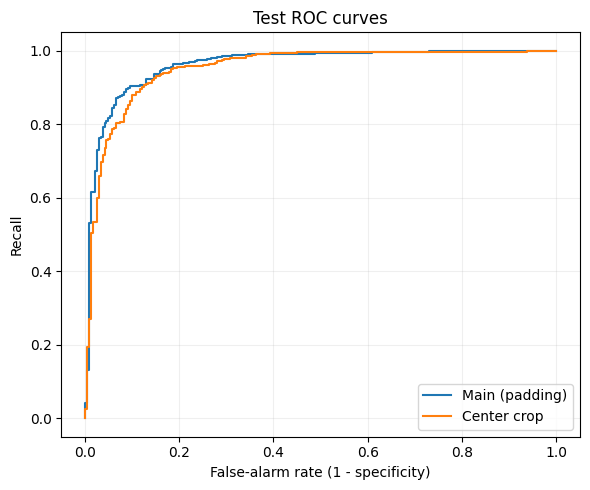

In [11]:
from sklearn.metrics import roc_curve

fpr_m, tpr_m, _ = roc_curve(y_test, prim_p)
fpr_c, tpr_c, _ = roc_curve(y_test, abl_test_p)

def spec_at_recall(fpr, tpr, target):
    return 1 - fpr[tpr >= target].min()

rows = [{"recall target": r,
         "main (padding)": spec_at_recall(fpr_m, tpr_m, r),
         "center crop": spec_at_recall(fpr_c, tpr_c, r)} for r in (0.90, 0.95, 0.98, 0.99)]
print("Specificity at the same recall (test, descriptive only):")
print(pd.DataFrame(rows).round(3).to_string(index=False))

plt.figure(figsize=(6, 5))
plt.plot(fpr_m, tpr_m, label="Main (padding)")
plt.plot(fpr_c, tpr_c, label="Center crop")
plt.xlabel("False-alarm rate (1 - specificity)"); plt.ylabel("Recall")
plt.title("Test ROC curves"); plt.legend(); plt.grid(alpha=0.2)
plt.tight_layout(); plt.show()

**Insights**
- At the same recall, the main model has equal or slightly higher specificity than the center-crop model at every level checked:
  0.904 vs 0.879 at recall 0.90, 0.833 vs 0.817 at 0.95, 0.721 vs 0.658 at 0.98, and 0.654 vs 0.638 at 0.99.
- The two ROC curves almost overlap, with the main model slightly above. This confirms that the crop model's higher specificity at threshold 0.50
  came from a different operating point (it missed more pneumonia cases), not from better discrimination.
- These differences are small compared with the uncertainty in the test set (specificity intervals are about ±6 points), so they are descriptive and not conclusive.
- **Takeaway:** removing the padding did not improve the model. The main model remains the primary result, and padding is not the main cause of the false alarms.

## 13. Conclusions and Limitations

### Main result (test set, 631 images, never used for training or tuning)
| Setting | Recall | Specificity | Precision | Accuracy | AUC |
|---|---|---|---|---|---|
| Threshold 0.50 | 0.985 | 0.700 | 0.843 | 0.876 | 0.962 |
| Threshold 0.29 (chosen on validation) | 0.992 | 0.596 | 0.800 | 0.842 | 0.962 |

95% intervals (patient-level bootstrap): AUC 0.944–0.976; at 0.50, recall 0.971–0.995 and specificity 0.637–0.760.

### What worked
- A patient-level split, with duplicates removed, gave a more trustworthy validation set than splitting by image.
- Two-stage transfer learning with EfficientNetB0 reached a validation AUC of 0.993.
- The model rarely misses pneumonia: 6 of 391 test cases at 0.50. Recall is similar for bacterial (0.984) and viral (0.986) pneumonia.

### What I found
- **Weakness:** on the test set the model over-calls pneumonia. Specificity is 0.70, against 0.95 on validation.
- **Image shape:** Normal X-rays that are wide (aspect ratio above 1.4) are flagged 3.6 times more often than narrower ones (53% vs 15%). The test set contains far more wide Normal images than the training data (40% vs 9%).
- **Grad-CAM:** the heatmaps do not always focus on the lungs. They sometimes land on chest-wall edges, devices or padding.
- **Experiment:** a center-crop model with no padding did not improve results, and the shape effect remained. Padding is therefore not the main cause.
- The threshold chosen on validation did not carry over to the test set.

### Limitations
- The test set differs from the training data, so test performance is lower than validation performance. I did not tune anything on the test set.
- The shape finding is an association, not proof of cause. Wide images may differ in scanner, hospital or patient age.
- Patient IDs come from filenames and could not be checked against real patient records.
- Validation was used to pick the best epoch, so validation numbers are slightly optimistic.
- The test set has only 240 Normal images, so specificity has wide uncertainty (about ±6 points).
- Each model was trained once. Repeating with several random seeds would show how stable the results are.
- The dataset appears to be pediatric chest X-rays from a single source (judging by its public description and the sample images), so results may not transfer to adults or other hospitals.
- Grad-CAM is coarse (a 7 × 7 map), and I did not have a clinician review the heatmaps.
- This is an educational project and not a diagnostic tool.

### Future work
- Test on an independent dataset from another hospital.
- Crop to the lung region automatically, so the model sees only the lungs.
- Train with more varied Normal images, matched to the test conditions.
- Average several models (an ensemble) and repeat with different seeds.